# Лекция 4: Слои, граф вычислений, батчи, инициализация, регуляризация и BatchNorm

**Что разберём:**

1. **Слои «с нуля»** — короткий разбор ООП в Python (класс как фабрика объектов, `self`, конструктор, наследование), затем Linear, ReLU, Sigmoid, Softmax, LogLoss на чистых Python-классах с методами `forward` и `backward`. Рядом с каждым слоем — формулы прямого прохода и градиентов.
2. **Граф вычислений** — нейросеть как *композиция функций*; градиент считается по **chain rule** (правилу цепочки), которую граф автоматизирует.
3. **Батчи** — зачем обучать на мини-батчах, что даёт параллелизм и как размер батча влияет на шум градиента и сходимость.
4. **Инициализация весов** — почему нули (и любые одинаковые инициализации) ломают обучение, что такое Xavier/He.
5. **Регуляризация** — зачем она и какие виды бывают (L2/L1, weight decay, dropout, early stopping, data augmentation).
6. **BatchNorm** — как работает, зачем нужны learnable `gamma`, `beta`, и почему обучение ускоряется.

**Идея лекции.** В лекции 3 мы вывели backprop «на бумаге» и один раз собрали сеть в функции. Сейчас мы сделаем то же самое **как инженеры**: каждый слой — это объект со своим `forward` и `backward`. Так устроены все реальные фреймворки (PyTorch, JAX), только у них это ускорено и автоматизировано.

> Всё, что мы пишем ниже — **чистый NumPy**. Никаких готовых слоёв, никакого autograd: каждый градиент выводим руками. Это лучший способ понять, что именно скрыто внутри `loss.backward()` в PyTorch.

**Обозначения (сквозные на всю лекцию):**

| Символ | Смысл |
|---|---|
| $n$ | число примеров в батче (batch size) |
| $d$ | размерность входа |
| $H$ | число нейронов в скрытом слое |
| $K$ | число классов |
| $X \in \mathbb{R}^{n \times d}$ | матрица входов (один пример — одна строка) |
| $Z = XW + b$ | «сырой» выход слоя (logits / pre-activation) |
| $A = \phi(Z)$ | выход после activation |
| $dZ, dW, dX$ | градиенты loss по соответствующим тензорам (той же формы, что сами тензоры) |

Главное правило форм: **градиент $dW$ всегда имеет ту же форму, что $W$** — это спасает от 90% ошибок при написании слоёв.

## Карта лекции

```text
   x ──► [ Linear ] ──► [ ReLU ] ──► [ Linear ] ──► [ Softmax+LogLoss ] ──► loss
          (1)             (1)          (1)              (1)
            │               │            │
            └───────────────┴────────────┴── все вместе = ГРАФ ВЫЧИСЛЕНИЙ (2)
                                                  ▲
              данные режем на БАТЧИ ──────────────┘ (3)
              веса стартуют с ИНИЦИАЛИЗАЦИИ ───────┘ (4)
              loss + РЕГУЛЯРИЗАЦИЯ ────────────────┘ (5)
              внутрь Linear вставляем BATCHNORM ───┘ (6)
```

Смотрим на картинку сети, которую будем собирать руками. Рёбра — это матрицы весов $W$, узлы — слои; именно по ним побегут значения вперёд и градиенты назад.

![Схема многослойной сети: входной слой, скрытые слои, выходной слой; рёбра — веса, которые мы будем хранить в классах](https://upload.wikimedia.org/wikipedia/commons/thumb/4/46/Colored_neural_network.svg/960px-Colored_neural_network.svg.png)

*Внешняя картинка: [Colored neural network](https://commons.wikimedia.org/wiki/File:Colored_neural_network.svg), Wikimedia Commons.*

---
# Часть 1. Слои с нуля: классы с `forward` и `backward`

Разберём, из чего собирается нейросеть «в железе»: каждый слой — это объект Python со своими методами `forward` и `backward`. Прежде чем писать эти методы, быстро вспомним сам механизм классов и объектов в Python.

## 1.0. Небольшое отступление: класс — это фабрика объектов

Прежде чем писать слои, вспомним, что такое **класс** в Python. Класс — это **чертёж (шаблон)**, по которому затем «отливаются» **объекты** — конкретные экземпляры.

- **Класс** описывает, *какие данные* будут у объекта (**атрибуты**) и *что он умеет* (**методы** — это обычные функции, у которых первый аргумент `self`).
- **Объект (экземпляр)** — конкретная «деталь» по этому чертежу. У каждого объекта **свои** значения атрибутов, но один и тот же набор методов.

```text
        класс (чертёж)                      объекты (изделия)
   ┌────────────────────────┐          ┌────────────┐   ┌────────────┐
   │  class Neuron:         │          │ Neuron #1  │   │ Neuron #2  │
   │      w, b      данные  │  ─────►  │ w = 0.5    │   │ w = -1.2   │
   │      forward()  метод  │          │ b = 0.1    │   │ b = 0.7    │
   └────────────────────────┘          └────────────┘   └────────────┘
              чертёж                    у каждого СВОИ w и b
```

Два ключевых механизма:

- **Конструктор `__init__`** — специальный метод, который вызывается автоматически при создании объекта `Neuron(...)` и раскладывает начальные значения по атрибутам.
- **`self`** — первый аргумент любого метода: это ссылка на **тот самый** объект, у которого метод вызван. Через `self.w = ...` в `__init__` мы заводим атрибут именно этого экземпляра.

Соберём маленький класс «нейрон» и убедимся, что экземпляры независимы.

In [1]:
# Класс - это чертёж. Создадим "нейрон" с весом и смещением: y = ReLU(w * x + b).
class Neuron:
    # один нейрон: хранит свои w, b и умеет считать forward

    def __init__(self, w, b):         # конструктор: вызывается при Neuron(...)
        self.w = w                    # атрибут экземпляра
        self.b = b

    def forward(self, x):             # метод; self - это конкретный объект
        z = self.w * x + self.b
        return z if z > 0 else 0.0    # нелинейность ReLU


n1 = Neuron(0.5, 0.1)                 # объект №1
n2 = Neuron(-1.2, 0.7)                # объект №2 - независимый, со своими w и b

print('n1:', f'w={n1.w}', f'b={n1.b}', '-> forward(2) =', n1.forward(2))
print('n2:', f'w={n2.w}', f'b={n2.b}', '-> forward(2) =', n2.forward(2))

n1.w = 10.0                           # меняем атрибут ТОЛЬКО у n1
print('после n1.w = 10.0:  n1.w =', n1.w, ' |  n2.w =', n2.w, '(n2 не изменился)')
print('type(n1):', type(n1).__name__, ' | n1 - экземпляр Neuron:', isinstance(n1, Neuron))

n1: w=0.5 b=0.1 -> forward(2) = 1.1
n2: w=-1.2 b=0.7 -> forward(2) = 0.0
после n1.w = 10.0:  n1.w = 10.0  |  n2.w = -1.2 (n2 не изменился)
type(n1): Neuron  | n1 - экземпляр Neuron: True


### 1.0.1. Наследование: один интерфейс — разные реализации

Классы умеют **наследоваться**: дочерний класс берёт всё от родителя и может **переопределить** его методы. Это даёт нам главное — писать общий код, который работает с *любым* слоем через единый интерфейс (`forward`/`backward`), не зная деталей реализации. Это называется **полиморфизм**.

```python
class Layer:                  # базовый класс = общий контракт
    def forward(self, x):
        raise NotImplementedError("наследник обязан реализовать forward")

class ReLU(Layer):            # дочерний класс
    def forward(self, x):     # переопределяем поведение
        return ...
```

Ровно такую схему мы и построим: базовый `Layer` задаёт контракт, а `Linear`, `ReLU`, `Softmax`, `BatchNorm`… — конкретные реализации.

In [2]:
# Наследование и полиморфизм: один базовый класс, разные реализации
class Activation:
    def forward(self, x):
        raise NotImplementedError('наследник должен реализовать forward')

    def __repr__(self):                    # как объект печатается в f-строке
        return f'{type(self).__name__}()'


class MyReLU(Activation):                  # учебная реализация (настоящий ReLU будет ниже)
    def forward(self, x):
        return x if x > 0 else 0.0


class Square(Activation):
    def forward(self, x):
        return x * x


# один и тот же вызов .forward() - а поведение разное (полиморфизм)
for act in [MyReLU(), Square()]:
    print(f'{act!r:>10}.forward(-3) = {act.forward(-3):>5.1f}    {act!r:>10}.forward(4) = {act.forward(4):.1f}')
print('оба - наследники Activation:',
      isinstance(MyReLU(), Activation), isinstance(Square(), Activation))

  MyReLU().forward(-3) =   0.0      MyReLU().forward(4) = 4.0
  Square().forward(-3) =   9.0      Square().forward(4) = 16.0
оба - наследники Activation: True True


### 1.1. Контракт слоя

Любой слой описываем одним и тем же интерфейсом:

```python
class Layer:
    def forward(self, x):       # вход -> выход, запоминаем всё нужное для backward
        ...
    def backward(self, dout):   # градиент loss по выходу -> градиент loss по входу
        ...
    def params(self):           # список обучаемых параметров (имя, значение, градиент)
        ...
```

Два правила, из которых всё следует:

1. **`forward` считает значения** $A = f(X)$ и запоминает то, что понадобится для производной (обычно промежуточный $Z$ или сам $A$). Память — плата за скорость.
2. **`backward` получает `dout` = $\partial J/\partial A$** и возвращает **$\partial J/\partial X$**, а $\partial J/\partial W$ и $\partial J/\partial b$ копит внутри `self`. Так градиент просто течёт назад по цепочке слоёв — это и есть backprop.

Слои пишем сразу батчевые: первый аргумент — матрица $X\in\mathbb{R}^{n\times d}$ (один пример = одна строка).

### 1.2. Инфраструктура: численная проверка градиента

Прежде чем писать слои, заведём инструменты, которыми будем **доказывать**, что наши формулы не врут:

- `describe(tensor)` — печатает форму и тип тензора;
- `numeric_grad(f, x, eps)` — «тупая» центральная разность $\dfrac{f(x+\varepsilon)-f(x-\varepsilon)}{2\varepsilon}$ по каждой координате. Работает только как эталон: требует двух forward на каждую координату;
- `check_grad(name, f, x0, analytic)` — сравнивает аналитический градиент с численным.

Это стандартный рабочий приём: сначала пишем `backward` руками, потом **обязательно** сверяем его численно. Любой, кто писал backprop, ловил баг именно так.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import ipywidgets as widgets
from IPython.display import display

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(42)


def describe(name, t):
    t = np.asarray(t)
    print(f'{name:>10} : shape={str(t.shape):>10}  dtype={t.dtype}')


def numeric_grad(f, x, eps=1e-6):
    '''Central-difference gradient of scalar f at array x. Slow - reference only.'''
    x = np.array(x, dtype=float)
    g = np.zeros_like(x)
    it = np.nditer(x, flags=['multi_index'])
    while not it.finished:
        i = it.multi_index
        old = x[i]
        x[i] = old + eps
        fp = f(x)
        x[i] = old - eps
        fm = f(x)
        x[i] = old
        g[i] = (fp - fm) / (2 * eps)
        it.iternext()
    return g


def check_grad(name, f, x0, analytic, atol=1e-6):  # x0: точка, где сравниваем
    '''Compare analytic gradient with numeric one; raise if mismatch.'''
    num = numeric_grad(f, np.array(x0, dtype=float))
    err = float(np.max(np.abs(num - analytic)))
    ok = err < atol
    print(f'[{"OK " if ok else "FAIL"}] {name:<20} max|analytic - numeric| = {err:.2e}  (tol {atol:.0e})')
    assert ok, f'gradient check FAILED: {name}'
    return num


print('numpy', np.__version__)
print('Инфраструктура готова — каждый backward будем проверять численно.')

numpy 1.21.2
Инфраструктура готова — каждый backward будем проверять численно.


---
## 1.3. Линейный слой (`Linear`)

Самый главный слой: он один несёт **все обучаемые параметры**. Это аффинное преобразование, нелинейности в нём нет.

**Прямой проход** (батч $X\in\mathbb{R}^{n\times d}$, веса $W\in\mathbb{R}^{d\times h}$, bias $b\in\mathbb{R}^{h}$):

$$Z = X W + b, \qquad z_{ij} = \sum_{k=1}^{d} x_{ik} w_{kj} + b_j$$

**Обратный проход.** На вход идёт $dZ = \partial J/\partial Z$ (форма $n\times h$). Выводим каждый градиент поэлементно:

$$\frac{\partial J}{\partial w_{kj}} = \sum_{i=1}^{n} \frac{\partial J}{\partial z_{ij}}\frac{\partial z_{ij}}{\partial w_{kj}}
= \sum_{i=1}^{n} dz_{ij}\, x_{ik}
\quad\Longrightarrow\quad
\boxed{\,dW = X^{\top} dZ\,}$$

$$\frac{\partial J}{\partial b_j} = \sum_{i=1}^{n} dz_{ij}\underbrace{\frac{\partial z_{ij}}{\partial b_j}}_{=1}
= \sum_{i=1}^{n} dz_{ij}
\quad\Longrightarrow\quad
\boxed{\,db = \textstyle\sum_{i} dZ\ \ (\text{сумма по строкам})\,}$$

Чтобы отдать градиент дальше вниз, нужен $\partial J/\partial X$ (форма $n\times d$):

$$\frac{\partial J}{\partial x_{ik}} = \sum_{j=1}^{h} dz_{ij} w_{kj}
\quad\Longrightarrow\quad
\boxed{\,dX = dZ\, W^{\top}\,}$$

**Проверка форм:** $X^{\top}$ это $d\times n$, а $dZ$ — $n\times h$, значит $dW$ — $d\times h$, ровно форма $W$. ✓

In [4]:
class Layer:
    '''Базовый контракт всех слоёв.'''
    eps = 1e-12

    def forward(self, x):
        raise NotImplementedError

    def backward(self, dout):
        raise NotImplementedError

    def params(self):
        return []


class Linear(Layer):
    '''Z = X @ W + b   |   dW = Xᵀ dZ,   db = sum(dZ),   dX = dZ Wᵀ'''

    def __init__(self, n_in, n_out, init='he', seed=0):
        r = np.random.default_rng(seed)
        if init == 'he':                       # N(0, 2/n_in)  - для ReLU (раздел 4)
            self.W = r.normal(0, np.sqrt(2.0 / n_in), size=(n_in, n_out))
        elif init == 'xavier':                 # N(0, 1/n_in)  - для tanh/sigmoid (раздел 4)
            self.W = r.normal(0, np.sqrt(1.0 / n_in), size=(n_in, n_out))
        elif init == 'zeros':                  # плохая инициализация (раздел 4)
            self.W = np.zeros((n_in, n_out))
        else:
            raise ValueError(init)
        self.b = np.zeros(n_out)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dZ):
        self.dW = self.x.T @ dZ              # (d×n) @ (n×h) = (d×h) = shape(W)
        self.db = dZ.sum(axis=0)             # (h,)
        return dZ @ self.W.T                 # (n×h) @ (h×d) = (n×d) = shape(X)

    def params(self):
        return [('W', self.W, self.dW), ('b', self.b, self.db)]


n, d, h = 4, 3, 5
X = np.random.default_rng(0).normal(size=(n, d))
lin = Linear(d, h, init='he', seed=1)
Z = lin.forward(X)
dZ_fake = np.random.default_rng(2).normal(size=(n, h))
dX = lin.backward(dZ_fake)

describe('X', X); describe('W', lin.W); describe('Z', Z)
describe('dZ', dZ_fake); describe('dW', lin.dW); describe('db', lin.db); describe('dX', dX)
print('\nключевое правило: shape(dW) == shape(W):', lin.dW.shape == lin.W.shape)
print('                 shape(dX) == shape(X):', dX.shape == X.shape)

         X : shape=    (4, 3)  dtype=float64
         W : shape=    (3, 5)  dtype=float64
         Z : shape=    (4, 5)  dtype=float64
        dZ : shape=    (4, 5)  dtype=float64
        dW : shape=    (3, 5)  dtype=float64
        db : shape=      (5,)  dtype=float64
        dX : shape=    (4, 3)  dtype=float64

ключевое правило: shape(dW) == shape(W): True
                 shape(dX) == shape(X): True


[OK ] Linear dW            max|analytic - numeric| = 7.34e-10  (tol 1e-06)
[OK ] Linear db            max|analytic - numeric| = 2.30e-11  (tol 1e-06)
[OK ] Linear dX            max|analytic - numeric| = 5.25e-10  (tol 1e-06)


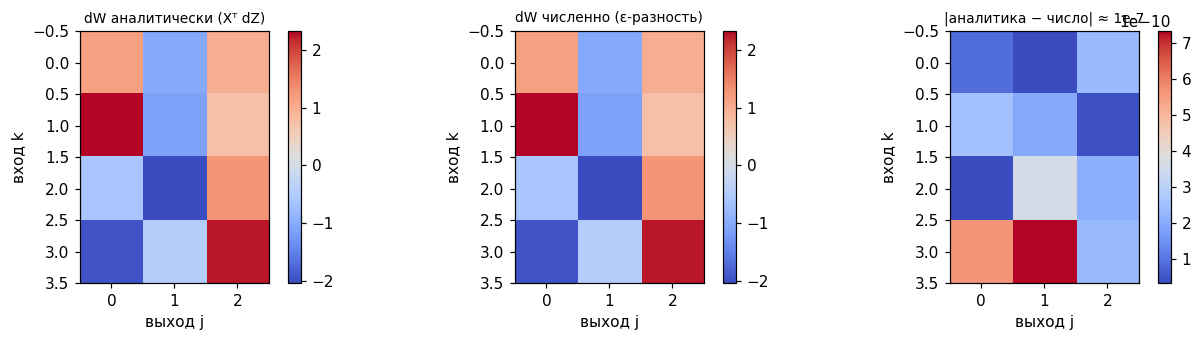

Формула dW = Xᵀ dZ подтверждена численно (левые два графика совпадают).


In [5]:
# ---- градиент-чек Linear ----
# Приём: если взять скалярный "верхний" loss  L = sum(Z * GZ)  с произвольным тензором GZ,
# то dL/dZ = GZ, и можно проверить сразу dW, db и dX.
r = np.random.default_rng(7)
Xc = r.normal(size=(6, 4))
GZ = r.normal(size=(6, 3))
linc = Linear(4, 3, init='he', seed=3)

linc.forward(Xc)
dX_an = linc.backward(GZ)
dW_an, db_an = linc.dW.copy(), linc.db.copy()

dW_num = numeric_grad(lambda W: np.sum((Xc @ W + linc.b) * GZ), linc.W.copy())
db_num = numeric_grad(lambda b: np.sum((Xc @ linc.W + b) * GZ), linc.b.copy())
dX_num = numeric_grad(lambda x: np.sum((x @ linc.W + linc.b) * GZ), Xc.copy())

check_grad('Linear dW', lambda W: np.sum((Xc @ W + linc.b) * GZ), linc.W, dW_an)
check_grad('Linear db', lambda b: np.sum((Xc @ linc.W + b) * GZ), linc.b, db_an)
check_grad('Linear dX', lambda x: np.sum((x @ linc.W + linc.b) * GZ), Xc, dX_an)
assert np.allclose(dW_an, dW_num) and np.allclose(db_an, db_num) and np.allclose(dX_an, dX_num)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, M_, t in zip(axes, [dW_an, dW_num, np.abs(dW_an - dW_num)],
                     ['dW аналитически (Xᵀ dZ)', 'dW численно (ε-разность)', '|аналитика − число| ≈ 1e-7']):
    im = ax.imshow(M_, cmap='coolwarm'); plt.colorbar(im, ax=ax)
    ax.set_title(t, fontsize=9); ax.set_xlabel('выход j'); ax.set_ylabel('вход k')
plt.tight_layout(); plt.show()
print('Формула dW = Xᵀ dZ подтверждена численно (левые два графика совпадают).')

---
## 1.4. ReLU (activation)

Activation не имеет параметров — она просто «изгибает» входящие значения. Самый популярный вариант — **ReLU**:

$$a = \phi(z) = \max(0, z) = \begin{cases} z, & z > 0\\ 0, & z \le 0\end{cases}$$

**Производная** — ступенька (субградиент в нуле берём $0$):

$$\frac{d\phi}{dz} = \begin{cases} 1, & z > 0\\ 0, & z \le 0\end{cases}
\qquad\Longrightarrow\qquad
\boxed{\,dZ = dA \odot \mathbb{1}[Z > 0]\,}$$

где $\odot$ — поэлементное умножение. Смысл: ReLU **пропускает градиент только по активным** нейронам ($z>0$); «закрытые» нейроны градиент не пропускают и сами не обучаются.

Плюсы: дёшево, не насыщается на положительной стороне (нет исчезающего градиента), даёт разреженные активации. Минус — «мёртвые» нейроны (те, что всегда $\le 0$ и навсегда получают нулевой градиент).

[OK ] ReLU dZ              max|analytic - numeric| = 1.44e-10  (tol 1e-06)


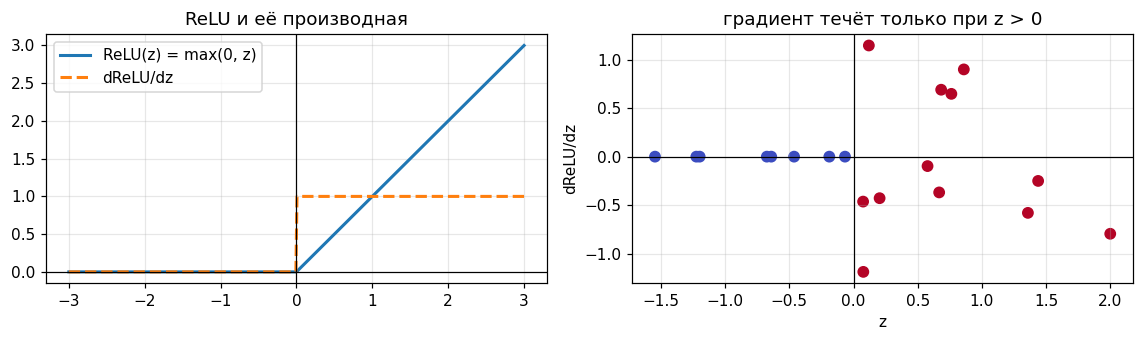

In [6]:
class ReLU(Layer):
    '''A = max(0, Z)   |   dZ = dA * 1[Z > 0]'''

    def forward(self, z):
        self.z = z
        return np.maximum(0.0, z)

    def backward(self, dA):
        return dA * (self.z > 0).astype(dA.dtype)


relu = ReLU()
Zc = r.normal(size=(5, 4))
A = relu.forward(Zc)
GA = r.normal(size=(5, 4))
dZ_an = relu.backward(GA)
check_grad('ReLU dZ', lambda z: np.sum(np.maximum(0.0, z) * GA), Zc, dZ_an)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
zline = np.linspace(-3, 3, 400)
axes[0].plot(zline, np.maximum(0, zline), lw=2, label='ReLU(z) = max(0, z)')
axes[0].plot(zline, np.where(zline > 0, 1, 0), lw=2, ls='--', label="dReLU/dz")
axes[0].axhline(0, color='k', lw=0.8); axes[0].axvline(0, color='k', lw=0.8)
axes[0].set_title('ReLU и её производная'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].scatter(Zc.ravel(), dZ_an.ravel(), c=(Zc.ravel() > 0), cmap='coolwarm', s=45)
axes[1].axhline(0, color='k', lw=0.8); axes[1].axvline(0, color='k', lw=0.8)
axes[1].set_title('градиент течёт только при z > 0')
axes[1].set_xlabel('z'); axes[1].set_ylabel('dReLU/dz'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## 1.5. Sigmoid

Sigmoid сжимает всю вещественную ось в интервал $(0, 1)$ — удобно, когда выход должен быть **вероятностью**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

**Производная** выводится в одну строку (один из самых полезных фактов в DL):

$$\frac{d\sigma}{dz} = \frac{e^{-z}}{(1+e^{-z})^2}
= \frac{1}{1+e^{-z}}\cdot\frac{e^{-z}}{1+e^{-z}}
= \sigma(z)\bigl(1-\sigma(z)\bigr) = a(1-a)$$

$$\boxed{\,dZ = dA \odot A \odot (1 - A)\,}$$

Производная **сама выражается через выход** $a$ — значит в `backward` достаточно сохранённого $A$, а $Z$ хранить не нужно. Максимум производной $\tfrac14$ при $z=0$; при $|z|\gtrsim 4$ она почти нулевая, поэтому глубокие стеки sigmoid страдают **исчезающим градиентом**: произведение многих множителей $<1$ уходит в ноль.

[OK ] Sigmoid dZ           max|analytic - numeric| = 1.17e-10  (tol 1e-06)


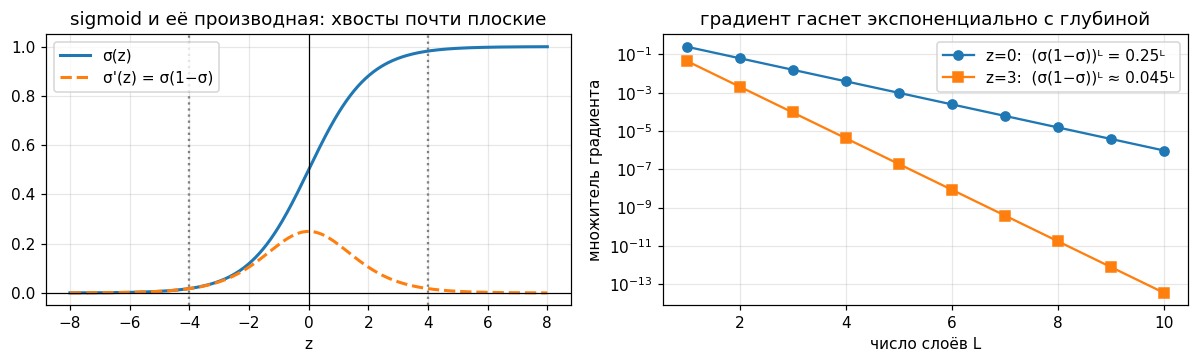

In [7]:
class Sigmoid(Layer):
    '''A = 1/(1+e^-Z)   |   dZ = dA * A * (1 - A)'''

    def forward(self, z):
        self.a = 1.0 / (1.0 + np.exp(-z))
        return self.a

    def backward(self, dA):
        return dA * self.a * (1.0 - self.a)


sig = Sigmoid()
Zc = r.normal(size=(5, 4))
A = sig.forward(Zc)
GA = r.normal(size=(5, 4))
dZ_an = sig.backward(GA)
check_grad('Sigmoid dZ', lambda z: np.sum((1/(1+np.exp(-z))) * GA), Zc, dZ_an)

zline = np.linspace(-8, 8, 500)
s = 1/(1+np.exp(-zline))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(zline, s, lw=2, label='σ(z)')
axes[0].plot(zline, s*(1-s), lw=2, ls='--', label="σ'(z) = σ(1−σ)")
axes[0].axhline(0, color='k', lw=0.8); axes[0].axvline(0, color='k', lw=0.8)
for xv in (-4, 4):
    axes[0].axvline(xv, color='gray', ls=':')
axes[0].set_title('sigmoid и её производная: хвосты почти плоские')
axes[0].legend(); axes[0].grid(alpha=0.3); axes[0].set_xlabel('z')

depths = np.arange(1, 11)
s3 = 1/(1+np.exp(-3.0))
axes[1].plot(depths, 0.25**depths, 'o-', label='z=0:  (σ(1−σ))ᴸ = 0.25ᴸ')
axes[1].plot(depths, (s3*(1-s3))**depths, 's-', label='z=3:  (σ(1−σ))ᴸ ≈ 0.045ᴸ')
axes[1].set_yscale('log'); axes[1].set_xlabel('число слоёв L'); axes[1].set_ylabel('множитель градиента')
axes[1].set_title('градиент гаснет экспоненциально с глубиной')
axes[1].legend(); axes[1].grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

---
## 1.6. Softmax

Softmax превращает вектор произвольных чисел («логитов») $z\in\mathbb{R}^{K}$ в **распределение вероятностей** по $K$ классам:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad \sum_k p_k = 1,\quad p_k > 0$$

Вычитание константы не меняет результат, поэтому на практике считают со сдвигом на максимум (иначе $e^{1000}$ переполнит `float64`):

$$p_k = \frac{e^{z_k - \max_j z_j}}{\sum_j e^{z_j - \max_j z_j}}$$

**Производная (якобиан).** Считаем $\partial p_k / \partial z_j$ правилом частного, два случая:

$$k = j:\ \ \frac{\partial p_k}{\partial z_k} = p_k(1 - p_k), \qquad\qquad
k \ne j:\ \ \frac{\partial p_k}{\partial z_j} = -p_k p_j$$

Вместе: $\dfrac{\partial p_k}{\partial z_j} = p_k(\delta_{kj} - p_j)$. Для backward нужен не сам якобиан $K\times K$, а произведение якобиана на верхний градиент $dP$:

$$\boxed{\,dZ = P \odot \Bigl(dP - \textstyle\sum_k dP_k P_k\Bigr)\,}\quad(\text{сумма по последней оси, broadcast по строкам})$$

Это дёшево: одна сумма и одно умножение.

[OK ] Softmax dZ           max|analytic - numeric| = 2.11e-10  (tol 1e-06)
наивно : [[nan nan nan]] -> nan из-за overflow
со сдвигом: [[0.09   0.2447 0.6652]] -> сумма = 1.000


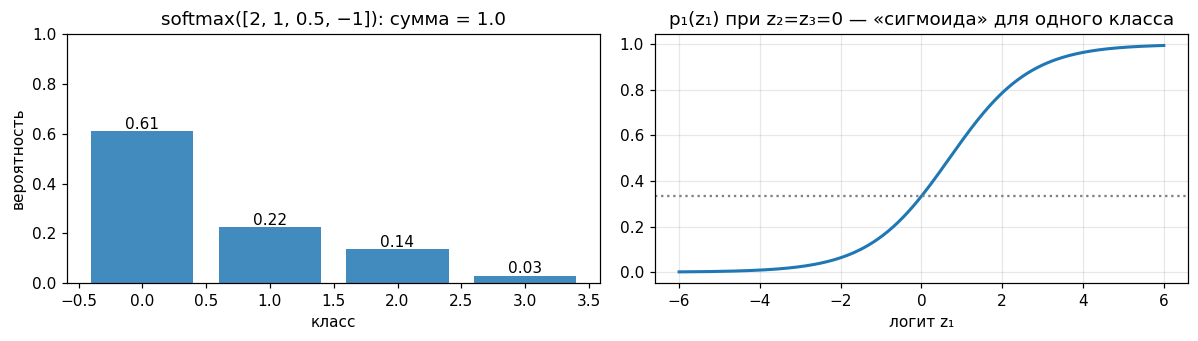

In [8]:
class Softmax(Layer):
    '''P = softmax(Z)   |   dZ = P * (dP - sum_k dP_k * P_k)'''

    def forward(self, z):
        z = z - z.max(axis=-1, keepdims=True)          # numerical stability
        e = np.exp(z)
        self.p = e / e.sum(axis=-1, keepdims=True)
        return self.p

    def backward(self, dP):
        return self.p * (dP - np.sum(dP * self.p, axis=-1, keepdims=True))


sm = Softmax()
Zc = r.normal(size=(4, 5))
P = sm.forward(Zc)
GP = r.normal(size=(4, 5))
dZ_an = sm.backward(GP)
check_grad('Softmax dZ', lambda z: np.sum(Softmax().forward(z) * GP), Zc, dZ_an)

big = np.array([[1000.0, 1001.0, 1002.0]])
with np.errstate(over='ignore', invalid='ignore'):
    naive = np.exp(big) / np.exp(big).sum()
print('наивно :', naive, '-> nan из-за overflow')
print('со сдвигом:', Softmax().forward(big), '-> сумма = %.3f' % Softmax().forward(big).sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
p0 = Softmax().forward(np.array([[2.0, 1.0, 0.5, -1.0]])).ravel()
axes[0].bar(range(4), p0, color='tab:blue', alpha=0.85)
for i, v in enumerate(p0):
    axes[0].text(i, v + 0.01, f'{v:.2f}', ha='center')
axes[0].set_title('softmax([2, 1, 0.5, −1]): сумма = 1.0')
axes[0].set_xlabel('класс'); axes[0].set_ylabel('вероятность'); axes[0].set_ylim(0, 1)

zk = np.linspace(-6, 6, 300)
curves = [Softmax().forward(np.array([[t, 0.0, 0.0]])).ravel()[0] for t in zk]
axes[1].plot(zk, curves, lw=2)
axes[1].axhline(1/3, color='gray', ls=':')
axes[1].set_title('p₁(z₁) при z₂=z₃=0 — «сигмоида» для одного класса')
axes[1].set_xlabel('логит z₁'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## 1.7. LogLoss (binary cross-entropy)

Loss — последний слой. Он **запускает backward**: его выход — скаляр $J$, и $\partial J/\partial J = 1$.

Для бинарной классификации есть вероятность $p\in(0,1)$ и метка $y\in\{0,1\}$. Negative log-likelihood (см. лекцию 3):

$$J = -\frac{1}{n}\sum_{i=1}^{n}\Bigl[y_i \log p_i + (1-y_i)\log(1-p_i)\Bigr]$$

**Градиент по $p$:**

$$\frac{\partial J}{\partial p} = -\frac{1}{n}\Bigl(\frac{y}{p} - \frac{1-y}{1-p}\Bigr)
= \frac{1}{n}\cdot\frac{p - y}{p\,(1 - p)}
\qquad\Longrightarrow\qquad
\boxed{\,dP = \frac{1}{n}\cdot\frac{P - Y}{P\,(1 - P)}\,}$$

Множитель $\tfrac1n$ — усреднение по батчу (поэтому в `Linear` мы уже ничего не делим).

**Почему $\log$, а не MSE?** Функции $-\log p$ и $-\log(1-p)$ уходят в $\infty$ при уверенной ошибке — модель получает сильный градиент ровно там, где ошибается сильнее всего. А в паре с sigmoid он сокращается: $\dfrac{dJ}{dz}=\dfrac{dJ}{dp}\cdot p(1-p)=\dfrac{p-y}{n}$ (это мы доказывали в лекции 3 — ниже перепроверим численно уже через классы).

[OK ] LogLoss dP           max|analytic - numeric| = 2.96e-11  (tol 1e-06)
J = 0.2990


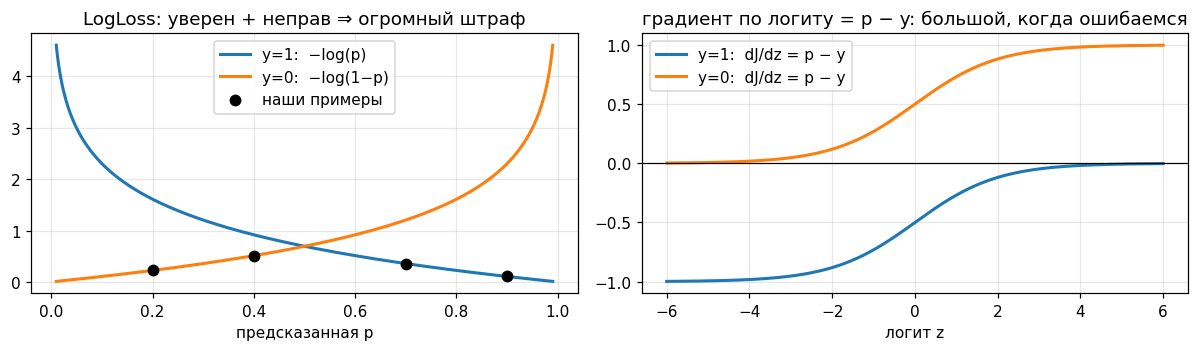

In [9]:
class LogLoss(Layer):
    '''J = -mean(y log p + (1-y) log(1-p))   |   dP = (P - Y) / (n * P * (1 - P))'''

    def forward(self, p, y):
        p = np.clip(p, self.eps, 1 - self.eps)
        self.p, self.y = p, y
        self.n = p.shape[0]
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def backward(self):
        return (self.p - self.y) / (self.n * self.p * (1 - self.p))


ll = LogLoss()
p_c = np.array([[0.9], [0.2], [0.7], [0.4]])
y_c = np.array([[1.0], [0.0], [1.0], [0.0]])
J = ll.forward(p_c, y_c)
dP_an = ll.backward()
check_grad('LogLoss dP', lambda p: -np.mean(y_c*np.log(p) + (1-y_c)*np.log(1-p)), p_c, dP_an)
print(f'J = {J:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
pp = np.linspace(0.01, 0.99, 400)
axes[0].plot(pp, -np.log(pp), label='y=1:  −log(p)', lw=2)
axes[0].plot(pp, -np.log(1-pp), label='y=0:  −log(1−p)', lw=2)
axes[0].scatter(p_c.ravel(),
                -(y_c.ravel()*np.log(p_c.ravel())+(1-y_c.ravel())*np.log(1-p_c.ravel())),
                c='k', zorder=5, s=45, label='наши примеры')
axes[0].set_title('LogLoss: уверен + неправ ⇒ огромный штраф')
axes[0].set_xlabel('предсказанная p'); axes[0].legend(); axes[0].grid(alpha=0.3)

zz = np.linspace(-6, 6, 400)
psig = 1/(1+np.exp(-zz))
axes[1].plot(zz, psig - 1, label='y=1:  dJ/dz = p − y', lw=2)
axes[1].plot(zz, psig - 0, label='y=0:  dJ/dz = p − y', lw=2)
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('градиент по логиту = p − y: большой, когда ошибаемся')
axes[1].set_xlabel('логит z'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 1.7.1. Мультиклассовый LogLoss и слитый слой `SoftmaxCrossEntropy`

Для $K$ классов метка — **one-hot** $y_k$, а loss — категориальная перекрёстная энтропия:

$$J = -\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{K} y_{ik}\log p_{ik} = -\frac{1}{n}\sum_{i=1}^{n}\log p_{i,\,y_i}$$

где $p=\mathrm{softmax}(Z)$. Градиент по вероятностям простой (важен только true-класс, где $y=1$):

$$\frac{\partial J}{\partial p_k} = -\frac{1}{n}\cdot\frac{y_k}{p_k}
\qquad\Longrightarrow\qquad
dP = -\frac{1}{n}\cdot\frac{Y}{P}\quad(\text{покомпонентно, с защитой от }0)$$

Теперь поставим `Softmax` и этот `CrossEntropy` подряд — в backward градиенты перемножатся и **всё сократится**. Выпишем цепочку: softmax-backward даёт $dZ_j = \sum_k p_j(\delta_{jk}-p_k)\,dP_k$, подставляем $dP_k = -y_k/(n p_k)$:

$$dZ_j = \frac{1}{n}\sum_k p_j(\delta_{jk}-p_k)\frac{y_k}{p_k}\cdot(-1)
= -\frac{1}{n}\Bigl(\sum_k y_k\delta_{jk} - p_j\sum_k y_k\Bigr)
= \frac{p_j - y_j}{n}$$

$$\boxed{\,dZ = \frac{P - Y}{n}\,}$$

Именно поэтому во всех фреймворках есть **один fused-слой**, который на forward считает loss, а на backward отдаёт $dZ=(P-Y)/n$. Он ещё и **численно устойчив**: считает через `logsumexp`, не строя промежуточные вероятности (там $Y/P$ мог бы делить на ноль). Это и есть `nn.CrossEntropyLoss` в PyTorch.

[OK ] SoftmaxCE dZ         max|analytic - numeric| = 9.55e-11  (tol 1e-06)
loss = 1.1230
строки dZ суммируются в 0: True
цепочка Softmax->CE == fused-слой: True


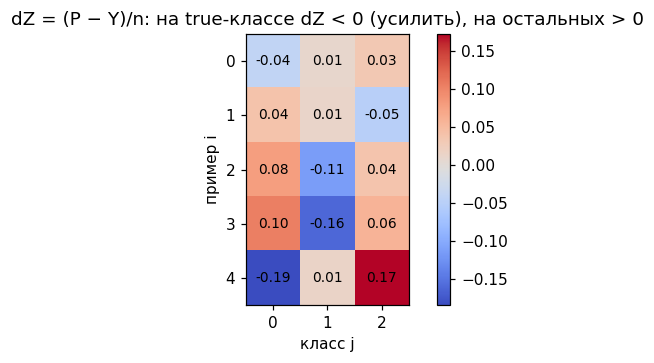

In [10]:
class SoftmaxCrossEntropy(Layer):
    '''Логиты Z -> loss.   |   dZ = (P - Y) / n   (softmax + CE сократились!)'''

    def forward(self, logits, y_int):
        z = logits - logits.max(axis=-1, keepdims=True)
        logsumexp = np.log(np.exp(z).sum(axis=-1, keepdims=True))   # численно устойчиво
        self.p = np.exp(z - logsumexp)
        self.n = logits.shape[0]
        self.Y = np.eye(logits.shape[1])[y_int]
        return np.mean(logsumexp.ravel() - z[np.arange(self.n), y_int])

    def backward(self):
        return (self.p - self.Y) / self.n


sce = SoftmaxCrossEntropy()
Zc = r.normal(size=(5, 3))
yint = np.array([0, 2, 1, 1, 0])
J = sce.forward(Zc, yint)
dZ_an = sce.backward()
check_grad('SoftmaxCE dZ', lambda z: SoftmaxCrossEntropy().forward(z, yint), Zc, dZ_an)
print(f'loss = {J:.4f}')
print('строки dZ суммируются в 0:', np.allclose(dZ_an.sum(axis=1), 0))

# сверяем: ручная цепочка Softmax -> CrossEntropy даёт тот же градиент (сокращение формул)
sm3 = Softmax()
p2 = sm3.forward(Zc)
Yc = np.eye(3)[yint]
dP_ce = -Yc / (len(yint) * p2)          # градиент CE по вероятностям p
dZ_chain = sm3.backward(dP_ce)
print('цепочка Softmax->CE == fused-слой:', np.allclose(dZ_chain, dZ_an, atol=1e-10))

# heatmap: dZ = (P - Y)/n, видно усиление истинного класса и ослабление остальных
fig, ax = plt.subplots(figsize=(5.4, 3.4))
im = ax.imshow(dZ_an, cmap='coolwarm')
for i in range(dZ_an.shape[0]):
    for j in range(dZ_an.shape[1]):
        ax.text(j, i, f'{dZ_an[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_xlabel('класс j'); ax.set_ylabel('пример i')
ax.set_title('dZ = (P − Y)/n: на true-классе dZ < 0 (усилить), на остальных > 0')
plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

### 1.8. Интерактив: почувствуйте forward и backward

Слева крутим логит одного нейрона: sigmoid даёт вероятность, а $p-y$ — градиент, который поедет назад. Справа крутим три логита softmax и смотрим вероятности и градиент `dZ = (P−Y)/n` при выбранном истинном классе.

In [11]:
def neuron_probe(z=0.0, y=1):
    p = 1/(1+np.exp(-z))
    grad = p - y
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.1))
    zz = np.linspace(-8, 8, 400)
    axes[0].plot(zz, 1/(1+np.exp(-zz)), lw=2)
    axes[0].scatter([z], [p], c='r', s=80, zorder=5)
    axes[0].annotate(f'p={p:.3f}', (z, p), textcoords='offset points', xytext=(8, -14))
    axes[0].axhline(y, color='g', ls='--', label=f'цель y={y}')
    axes[0].set_title('forward: sigmoid(logit) = вероятность')
    axes[0].set_xlabel('логит z'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(zz, 1/(1+np.exp(-zz)) - y, lw=2, color='tab:red')
    axes[1].scatter([z], [grad], c='k', s=80, zorder=5)
    axes[1].axhline(0, color='k', lw=0.8)
    axes[1].set_title(f'backward: dJ/dz = p − y = {grad:.3f}')
    axes[1].set_xlabel('логит z'); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def softmax_probe(z0=2.0, z1=1.0, z2=0.0, true_class=0):
    logits = np.array([[z0, z1, z2]])
    sce_ = SoftmaxCrossEntropy()
    _ = sce_.forward(logits, np.array([true_class]))
    p = sce_.p.ravel(); dz = sce_.backward().ravel()
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.1))
    axes[0].bar(['класс 0', 'класс 1', 'класс 2'], p, color=['tab:blue', 'tab:orange', 'tab:green'], alpha=0.85)
    for i, v in enumerate(p):
        axes[0].text(i, v + 0.01, f'{v:.2f}', ha='center')
    axes[0].set_ylim(0, 1); axes[0].set_title('forward: softmax(logits)'); axes[0].set_ylabel('вероятность')

    colors = ['tab:red' if i == true_class else 'tab:gray' for i in range(3)]
    axes[1].bar(['класс 0', 'класс 1', 'класс 2'], dz, color=colors, alpha=0.85)
    axes[1].axhline(0, color='k', lw=0.8)
    axes[1].set_title(f'backward: dZ = (P−Y)/n,  истинный класс = {true_class}')
    axes[1].set_ylabel('dZ'); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


display(widgets.interact(neuron_probe,
        z=widgets.FloatSlider(value=0.0, min=-8, max=8, step=0.1, description='logit z'),
        y=widgets.Dropdown(options=[0, 1], value=1, description='метка y')))

display(widgets.interact(softmax_probe,
        z0=widgets.FloatSlider(value=2.0, min=-5, max=5, step=0.1, description='z₀'),
        z1=widgets.FloatSlider(value=1.0, min=-5, max=5, step=0.1, description='z₁'),
        z2=widgets.FloatSlider(value=0.0, min=-5, max=5, step=0.1, description='z₂'),
        true_class=widgets.Dropdown(options=[0, 1, 2], value=0, description='истинный')))

interactive(children=(FloatSlider(value=0.0, description='logit z', max=8.0, min=-8.0), Dropdown(description='…

<function __main__.neuron_probe(z=0.0, y=1)>

interactive(children=(FloatSlider(value=2.0, description='z₀', max=5.0, min=-5.0), FloatSlider(value=1.0, desc…

<function __main__.softmax_probe(z0=2.0, z1=1.0, z2=0.0, true_class=0)>

### 1.9. Итог по части 1: шпаргалка формул

| Слой | forward | backward |
|---|---|---|
| **Linear** $Z = XW+b$ | $Z = XW + b$ | $dW = X^{\top}dZ$ (копим), $db = \sum_i dZ$ (копим), $dX = dZ\,W^{\top}$ |
| **ReLU** | $A = \max(0,Z)$ | $dZ = dA \odot \mathbb{1}[Z>0]$ |
| **Sigmoid** | $A = \sigma(Z)$ | $dZ = dA \odot A(1-A)$ |
| **Softmax** | $P = \dfrac{e^{Z}}{\sum e^{Z}}$ | $dZ = P\odot\bigl(dP - \sum_k dP_k P_k\bigr)$ |
| **LogLoss** (BCE) | $J = -\frac1n\sum[y\log p + (1-y)\log(1-p)]$ | $dP = \frac{1}{n}\frac{P-Y}{P(1-P)}$ |
| **Softmax+CE** (fused) | $J = -\frac1n\sum\log p_{y_i}$ | $dZ = \frac{P-Y}{n}$ |

Каждый `backward` мы проверили **численно** — это взрослый способ убедиться, что слой написан правильно.

---
# Часть 2. Граф вычислений: сеть как композиция функций

## 2.1. Композиция функций и chain rule

Начнём с главной мысли. **Нейросеть — это композиция функций.** Наш MLP из части 1 — не что иное, как

$$J(x) = \underbrace{\text{Loss}}_{\text{последний слой}}\Bigl(
       \underbrace{\phi_2}_{\text{activation}}\bigl(
       \underbrace{W_2}_{\text{Linear}}\,
       \underbrace{\phi_1}_{\text{activation}}\bigl(W_1 x + b_1\bigr) + b_2 \bigr)\Bigr)$$

То есть $J(x) = (f_L \circ f_{L-1} \circ \dots \circ f_1)(x)$, где каждая $f_\ell$ — один слой.

Раз мы хотим учиться градиентным спуском, нам нужен $\dfrac{\partial J}{\partial \theta}$ для **каждого** параметра $\theta$. И здесь работает **chain rule** (правило цепочки). Для скалярной цепочки:

$$\frac{dJ}{dx} = \frac{dJ}{df_L}\cdot\frac{df_L}{df_{L-1}}\cdots\frac{df_2}{df_1}\cdot\frac{df_1}{dx}
= \prod_{\ell=1}^{L}\frac{df_\ell}{df_{\ell-1}}$$

Смысл: **каждый слой домножает градиент на свой локальный наклон**. Ровно это делает `backward` — возвращает $\partial J/\partial X$, а $\partial J/\partial W$ копит у себя. Проходя цепочку назад, мы автоматически получаем градиенты всех параметров.

Аналогия с шестерёнками: ручка $x$ крутит шестерёнку $f_1$, та — $f_2$, …, последняя — $J$. Общее передаточное число = произведение передаточных чисел шестерёнок.

## 2.2. Граф вычислений: картинка

Скучную цепочку удобно рисовать как **граф вычислений**: узлы — тензоры, стрелки — операции.

```text
        X      W₁,b₁            W₂,b₂
        │        │               │
        ▼        ▼               ▼
   ┌─────────────────┐     ┌──────────┐
   │ Z₁ = X @ W₁ + b₁│────►│ ReLU: A₁ │
   └─────────────────┘     └──────────┘
                                 │
                                 ▼
                          ┌──────────────┐
                          │ Z₂ = A₁@W₂+b₂│
                          └──────────────┘
                                 │
                                 ▼
                   ┌───────────────────────────┐
                   │ Loss = SoftmaxCE(Z₂, y)   │  ← скаляр J
                   └───────────────────────────┘

   FORWARD (чёрные стрелки):  значения →  считаем J
   BACKWARD (красные стрелки): градиенты ←  получаем dW₁, dW₂, db₁, db₂
```

Два свойства графа, которыми пользуется backprop:

1. **Forward идёт в топологическом порядке** — можно считать узел, только когда посчитаны все его «родители».
2. **Backward идёт в обратном порядке и накапливает градиенты**: если тензор влияет на loss по нескольким путям, вклады **складываются** (это тоже chain rule: $\frac{dJ}{dx}=\sum_{\text{путей}} \dots$).

![Схема графа нейросети: узлы — тензоры, рёбра — операции](https://upload.wikimedia.org/wikipedia/commons/thumb/9/91/Multi-Layer_Neural_Network-Vector.svg/960px-Multi-Layer_Neural_Network-Vector.svg.png)

*Внешняя картинка: [Multi-Layer Neural Network-Vector](https://commons.wikimedia.org/wiki/File:Multi-Layer_Neural_Network-Vector.svg), Wikimedia Commons.*

## 2.3. Реализация: `Sequential` — граф из наших слоёв

Последовательность слоёв — самый частый граф:

`x → layer₁ → layer₂ → … → layer_L`

`forward` просто прогоняет тензор по цепочке вперёд, `backward` — по цепочке назад. **Никакого нового кода для градиента не нужно**: достаточно, что каждый слой умеет `backward`, а chain rule говорит «перемножай локальные наклоны вдоль цепочки».

In [12]:
class Sequential(Layer):
    '''Композиция слоёв: f = f_L ∘ ... ∘ f_1. forward - вперёд, backward - назад.'''

    def __init__(self, *layers):
        self.layers = list(layers)

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)           # композиция функций
        return x

    def backward(self, dout):
        for layer in reversed(self.layers):  # chain rule в обратном порядке
            dout = layer.backward(dout)
        return dout

    def params(self):
        out = []
        for layer in self.layers:
            out += layer.params()
        return out

    def zero_grad(self):
        for _, _, grad in self.params():
            grad[...] = 0.0

    def sgd_step(self, lr):
        for _, val, grad in self.params():
            val -= lr * grad


def make_mlp(d_in, H, K, seed=0, init='he'):
    '''Простой 3-слойный граф: Linear -> ReLU -> Linear (выходные логиты).'''
    return Sequential(
        Linear(d_in, H, init=init, seed=seed),
        ReLU(),
        Linear(H, K, init=init, seed=seed + 1),
    )


net = make_mlp(2, 8, 3, seed=0)
Xg = np.random.default_rng(0).normal(size=(5, 2))
logits = net.forward(Xg)
print('формы по цепочке:', Xg.shape, '->', logits.shape)
print('число обучаемых тензоров:', len(net.params()))
for name, val, grad in net.params():
    print(f'   {name:>2}: value{val.shape}  grad{grad.shape}')

формы по цепочке: (5, 2) -> (5, 3)
число обучаемых тензоров: 4
    W: value(2, 8)  grad(2, 8)
    b: value(8,)  grad(8,)
    W: value(8, 3)  grad(8, 3)
    b: value(3,)  grad(3,)


### 2.4. Проверка: chain rule через классы == численный градиент

Проверим, что `Sequential.backward` действительно даёт верный градиент loss по **всем** параметрам. Возьмём сеть 2→4→3, batch из 5 точек, loss `SoftmaxCrossEntropy`. Соберём аналитические градиенты всех параметров, а численный — численно «потрясём» каждый параметр.

Единственная тонкость: `backward` у слоя принимает **верхний** градиент, а loss-слой его выдаёт сам. Поэтому порядок такой: `softmaxCE.forward` → `softmaxCE.backward()` → `net.backward(dZ)`.

In [13]:
def flatten_params(net):
    '''Собирает все (name, value, grad) в плоские копии для численной проверки.'''
    return net.params()


def loss_of(net, X, y):
    '''Полный forward до скалярного loss.'''
    logits = net.forward(X)
    return SoftmaxCrossEntropy().forward(logits, y)


r = np.random.default_rng(1)
Xn = r.normal(size=(6, 2))
yn = np.array([0, 2, 1, 1, 0, 2])
net = make_mlp(2, 4, 3, seed=5)

# ---- аналитический градиент всего графа ----
logits = net.forward(Xn)
sce = SoftmaxCrossEntropy()
J = sce.forward(logits, yn)
net.zero_grad()
net.backward(sce.backward())
# ВАЖНО: у обоих Linear имена параметров совпадают ('W','b'), поэтому храним по позиции
params = net.params()
analytic = [grad.copy() for _, val, grad in params]
print(f'loss = {J:.4f}')
print('тензоров с градиентом:', len(analytic), '(2 Linear × (W, b))')

# ---- численно по каждому параметру ----
for (name, val, grad), ref in zip(params, analytic):
    def f_flat(flat, val=val):
        saved = val.copy()
        val[...] = flat
        out = loss_of(net, Xn, yn)
        val[...] = saved
        return out
    check_grad(f'graph d{name}', f_flat, val, ref, atol=1e-5)

print('\nВердикт: chain rule, реализованный классами, совпал с численным градиентом.')

loss = 1.3674
тензоров с градиентом: 4 (2 Linear × (W, b))
[OK ] graph dW             max|analytic - numeric| = 1.32e-10  (tol 1e-05)
[OK ] graph db             max|analytic - numeric| = 1.69e-10  (tol 1e-05)
[OK ] graph dW             max|analytic - numeric| = 1.90e-10  (tol 1e-05)
[OK ] graph db             max|analytic - numeric| = 2.38e-10  (tol 1e-05)

Вердикт: chain rule, реализованный классами, совпал с численным градиентом.


## 2.5. Своя мини-autograd: граф «по-настоящему»

`Sequential` — это линейный граф. Настоящие фреймворки умеют графы **произвольной формы**: узел может влиять на loss по нескольким путям, и тогда градиенты **складываются**. Реализуем крошечный autograd, чтобы увидеть это своими глазами — именно так устроен `torch.autograd`.

Идея в 10 строках:

1. Узел `Node` хранит значение, список «родителей» и функцию локальных производных.
2. `backward` делает топологическую сортировку, идёт **в обратном** порядке и **накапливает** градиенты в родителей.
3. Операции (`+`, `@`, `relu`, `sigmoid`, `softmax_ce`) просто описывают свой локальный наклон.

Операции над `Node` можно писать как обычные `+` и `@` — синтаксис как в PyTorch, но весь код на 40 строк ниже.

In [14]:
class Node:
    '''Мини-тензор с поддержкой reverse-mode autodiff.'''

    def __init__(self, value, parents=(), vjp=None, name=''):
        self.value = np.asarray(value, dtype=float)
        self.parents = tuple(parents)       # рёбра графа: кто на нас влияет
        self.vjp = vjp                      # vector-Jacobian product: g -> grads по родителям
        self.name = name
        self.grad = np.zeros_like(self.value)

    # --- арифметика: каждая операция добавляет узел в граф ---
    def __add__(self, other):
        other = as_node(other)
        return Node(self.value + other.value, (self, other), lambda g: (g, g), 'add')

    def __mul__(self, other):
        other = as_node(other)
        return Node(self.value * other.value, (self, other),
                    lambda g: (g * other.value, g * self.value), 'mul')

    def __matmul__(self, other):
        other = as_node(other)
        return Node(self.value @ other.value, (self, other),
                    lambda g: (g @ other.value.T, self.value.T @ g), 'matmul')

    def relu(self):
        mask = (self.value > 0).astype(float)
        return Node(np.maximum(0, self.value), (self,), lambda g: (g * mask,), 'relu')


def as_node(v):
    return v if isinstance(v, Node) else Node(v)


def unbroadcast(g, shape):
    '''Складывает градиент обратно к форме параметра (для bias и скаляров).'''
    while g.ndim > len(shape):
        g = g.sum(axis=0)
    for i, s in enumerate(shape):
        if s == 1 and g.shape[i] != 1:
            g = g.sum(axis=i, keepdims=True)
    return g.reshape(shape)


def add_bias(x, b):
    '''Z = X @ W + b с корректным градиентом по b (широковещание).'''
    def vjp(g):
        return (g, unbroadcast(g, b.value.shape))
    return Node(x.value + b.value, (x, b), vjp, 'add_bias')


def softmax_ce(logits, y_int):
    z = logits.value - logits.value.max(axis=-1, keepdims=True)
    lse = np.log(np.exp(z).sum(axis=-1, keepdims=True))
    p = np.exp(z - lse)
    Y = np.eye(logits.value.shape[1])[y_int]
    n = logits.value.shape[0]
    loss = np.mean(lse.ravel() - z[np.arange(n), y_int])
    return Node(loss, (logits,), lambda g: (g * (p - Y) / n,), 'sce')


def backward(root):
    '''Обратный проход по графу: топосортировка + накопление градиентов.'''
    topo, seen = [], set()

    def dfs(node):
        if id(node) in seen:
            return
        seen.add(id(node))
        for parent in node.parents:
            dfs(parent)
        topo.append(node)

    dfs(root)
    for node in topo:
        node.grad = np.zeros_like(node.value)
    root.grad = np.ones_like(root.value)
    for node in reversed(topo):                 # обратный топологический порядок
        if node.vjp is not None:
            for parent, g in zip(node.parents, node.vjp(node.grad)):
                parent.grad = parent.grad + g   # НАКОПЛЕНИЕ вкладов по всем путям
    return {id(n): n.grad for n in topo}


print('Готово: Node, add_bias, softmax_ce, backward — свой autograd в 40 строк.')

Готово: Node, add_bias, softmax_ce, backward — свой autograd в 40 строк.


### 2.6. Тот же граф, но собранный из `Node`

Соберём сеть 2→4→3 через `Node` и убедимся, что она даёт **те же градиенты**, что и `Sequential`. Ручной autograd и наши слои — две реализации одного и того же chain rule.

In [15]:
# параметры тоже узлы графа (листья, у которых grad накапливается)
r = np.random.default_rng(3)
W1 = Node(r.normal(0, np.sqrt(2/2), size=(2, 4)), name='W1')
b1 = Node(np.zeros(4), name='b1')
W2 = Node(r.normal(0, np.sqrt(2/4), size=(4, 3)), name='W2')
b2 = Node(np.zeros(3), name='b2')

Xn2 = r.normal(size=(6, 2))
yn2 = np.array([0, 2, 1, 1, 0, 2])

# forward: собираем граф
X_node = Node(Xn2, name='X')
Z1 = add_bias(X_node @ W1, b1)
A1 = Z1.relu()
Z2 = add_bias(A1 @ W2, b2)
loss = softmax_ce(Z2, yn2)

grads = backward(loss)
print(f'loss (autograd) = {loss.value:.6f}')

# та же сеть нашими классами
net2 = Sequential(Linear(2, 4, seed=3), ReLU(), Linear(4, 3, seed=4))
net2.layers[0].W = W1.value.copy(); net2.layers[0].b = b1.value.copy()
net2.layers[1] = ReLU()
net2.layers[2].W = W2.value.copy(); net2.layers[2].b = b2.value.copy()

lg = net2.forward(Xn2)
sce = SoftmaxCrossEntropy(); J2 = sce.forward(lg, yn2)
net2.zero_grad(); net2.backward(sce.backward())
print(f'loss (Sequential) = {J2:.6f}   (совпадает: {np.isclose(loss.value, J2)})')

for node, name, ref in [(W1, 'W1', net2.layers[0].dW), (b1, 'b1', net2.layers[0].db),
                        (W2, 'W2', net2.layers[2].dW), (b2, 'b2', net2.layers[2].db)]:
    same = np.allclose(node.grad, ref, atol=1e-10)
    print(f'  d{name}: autograd == Sequential -> {same}   (shape {node.grad.shape})')
    assert same
print('\nДве независимые реализации chain rule дали одинаковый градиент.')

loss (autograd) = 1.186509
loss (Sequential) = 1.186509   (совпадает: True)
  dW1: autograd == Sequential -> True   (shape (2, 4))
  db1: autograd == Sequential -> True   (shape (4,))
  dW2: autograd == Sequential -> True   (shape (4, 3))
  db2: autograd == Sequential -> True   (shape (3,))

Две независимые реализации chain rule дали одинаковый градиент.


## 2.7. Визуализация графа: значения вперёд, градиенты назад

Нарисуем граф маленькой сети и подпишем каждый узел: **чёрным — значение из forward, красным — градиент из backward**. Видно, как градиент «течёт» от loss назад и что на каждом слое он домножается на локальный множитель (это и есть chain rule).

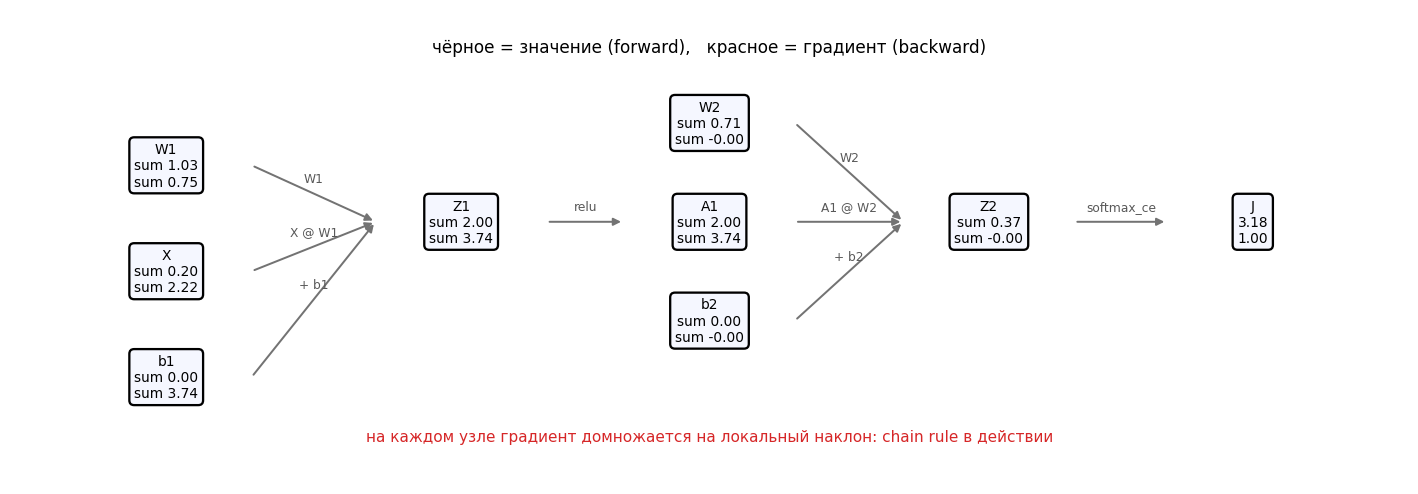

loss = 3.1752
  dW1 =
[[ 0.336  1.392  0.892]
 [-0.24  -0.994 -0.637]]
  db1 =
[0.48  1.989 1.275]
  dW2 =
[[ 0.214 -0.214]
 [ 0.844 -0.844]
 [ 0.859 -0.859]]
  db2 =
[ 0.958 -0.958]


In [16]:
# маленькая сеть на 2 входа, чтобы граф был читаемым
r = np.random.default_rng(11)
x1, x2 = 0.7, -0.5
Xn3 = np.array([[x1, x2]])
yn3 = np.array([1])

W1n = Node(r.normal(0, 0.8, size=(2, 3)), name='W1')
b1n = Node(np.zeros(3), name='b1')
W2n = Node(r.normal(0, 0.8, size=(3, 2)), name='W2')
b2n = Node(np.zeros(2), name='b2')

Xnode = Node(Xn3, name='X')
Z1n = add_bias(Xnode @ W1n, b1n, )
A1n = Z1n.relu()
Z2n = add_bias(A1n @ W2n, b2n)
lossn = softmax_ce(Z2n, yn3)
grads = backward(lossn)

# рисуем граф
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.axis('off')
positions = {
    'X': (0.0, 1.5), 'W1': (0.0, 3.0), 'b1': (0.0, 0.0),
    'Z1': (1.9, 2.2), 'A1': (3.5, 2.2), 'W2': (3.5, 3.6), 'b2': (3.5, 0.8),
    'Z2': (5.3, 2.2), 'J': (7.0, 2.2),
}
nodes = {'X': Xnode, 'W1': W1n, 'b1': b1n, 'Z1': Z1n, 'A1': A1n,
         'W2': W2n, 'b2': b2n, 'Z2': Z2n, 'J': lossn}
edges = [('X', 'Z1', 'X @ W1'), ('W1', 'Z1', 'W1'), ('b1', 'Z1', '+ b1'),
         ('Z1', 'A1', 'relu'), ('A1', 'Z2', 'A1 @ W2'), ('W2', 'Z2', 'W2'),
         ('b2', 'Z2', '+ b2'), ('Z2', 'J', 'softmax_ce')]
for a, b_, lab in edges:
    xa, ya = positions[a]; xb, yb = positions[b_]
    ax.annotate('', xy=(xb - 0.55, yb), xytext=(xa + 0.55, ya),
                arrowprops=dict(arrowstyle='-|>', color='0.45', lw=1.3))
    ax.text((xa + xb)/2, (ya + yb)/2 + 0.16, lab, ha='center', fontsize=8, color='0.35')
for k, (px, py) in positions.items():
    node = nodes[k]
    val = node.value
    vtxt = f'{val:.2f}' if val.size == 1 else f'sum {val.sum():.2f}'
    gtxt = f'{node.grad:.2f}' if node.grad.size == 1 else f'sum {node.grad.sum():.2f}'
    ax.text(px, py, f'{k}\n{vtxt}\n{gtxt}', ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.35', fc='#f5f7ff', ec='k', lw=1.5))
ax.text(3.5, 4.6, 'чёрное = значение (forward),   красное = градиент (backward)',
        ha='center', fontsize=11, color='k')
ax.text(3.5, -0.9, 'на каждом узле градиент домножается на локальный наклон: chain rule в действии',
        ha='center', fontsize=10, color='tab:red')
ax.set_xlim(-1, 8); ax.set_ylim(-1.5, 5.2)
plt.tight_layout(); plt.show()
print('loss =', round(float(lossn.value), 4))
for name, node in [('dW1', W1n), ('db1', b1n), ('dW2', W2n), ('db2', b2n)]:
    print(f'  {name} =\n{np.round(node.grad, 3)}')

### 2.8. Chain rule как произведение локальных наклонов

Проверим численно на **одной точке**, что произведение локальных производных равно итоговому градиенту — то есть что обратный проход по графу честно считает $\partial J/\partial \theta = \prod_\ell \frac{\partial f_\ell}{\partial f_{\ell-1}}$.

Проще всего увидеть это на масштабе: насколько изменится loss, если чуть-чуть подёргать **первый** слой, предсказывается цепочкой «верхних» градиентов. Сравним с численной производной.

произведение локальных наклонов = 5.127314
численный dJ/dx                 = 5.127314
совпало: True


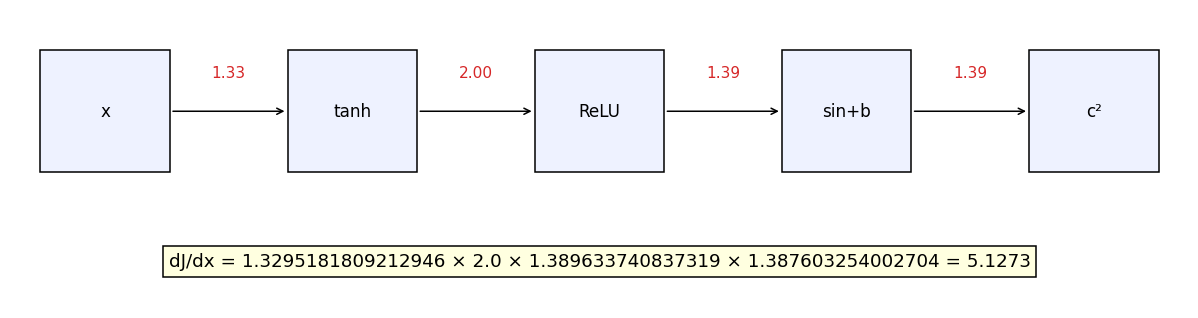

In [17]:
# возьмём слоистую функцию и проверим накопление множителей
def f_chain(x):
    a = np.tanh(1.5 * x + 0.3)      # слой 1
    b = np.maximum(0, 2.0 * a - 0.2)  # слой 2
    c = np.sin(b) + 0.5 * b          # слой 3
    return np.sum(c ** 2)

xs = np.linspace(-2, 2, 60)
first = xs[30]
# локальные производные
a = np.tanh(1.5 * first + 0.3)
da = (1 - a**2) * 1.5
b = max(0.0, 2.0 * a - 0.2)
db = 2.0 * (b > 0)
c = np.sin(b) + 0.5 * b
dc = (np.cos(b) + 0.5)
prod = 2 * c * dc * db * da
num = numeric_grad(lambda v: f_chain(v[0]), np.array([first]))[0]
print(f'произведение локальных наклонов = {prod:.6f}')
print(f'численный dJ/dx                 = {num:.6f}')
print('совпало:', np.isclose(prod, num, atol=1e-5))

fig, ax = plt.subplots(figsize=(11, 3.0))
ax.axis('off')
labels = ['x', 'tanh', 'ReLU', 'sin+b', 'c²']
locals_ = ['', f'{da:.2f}', f'{db:.2f}', f'{dc:.2f}', f'{2*c:.2f}']
xs_pos = np.linspace(0.8, 9.2, 5)
for i, (px, lb, lc) in enumerate(zip(xs_pos, labels, locals_)):
    ax.add_patch(plt.Rectangle((px - 0.55, 1.2), 1.1, 0.9, fc='#eef2ff', ec='k'))
    ax.text(px, 1.65, lb, ha='center', va='center', fontsize=11)
    if i > 0:
        ax.annotate('', xy=(px - 0.55, 1.65), xytext=(xs_pos[i-1] + 0.55, 1.65),
                    arrowprops=dict(arrowstyle='->', color='k'))
        ax.text((px + xs_pos[i-1]) / 2, 1.9, lc, ha='center', fontsize=10, color='tab:red')
ax.text(5.0, 0.5, f'dJ/dx = {" × ".join([f"{v}" for v in [da, db, dc, 2*c]])} = {prod:.4f}',
        ha='center', fontsize=12, bbox=dict(fc='lightyellow', ec='k'))
ax.set_xlim(0, 10); ax.set_ylim(0.2, 2.4)
plt.tight_layout(); plt.show()

## 2.9. Итог по части 2

- Нейросеть = **композиция функций** $J = f_L \circ \dots \circ f_1$.
- Градиент = **chain rule** = произведение локальных наклонов вдоль пути (и сумма — если путей несколько).
- Граф вычислений автоматизирует это: `forward` в топологическом порядке, `backward` — в обратном, с накоплением.
- Мы реализовали это двумя способами: `Sequential` (цепочка слоёв с `forward`/`backward`) и мини-`autograd` (`Node` + `backward`), и оба дали одинаковый градиент, совпавший с численным.

Теперь у нас есть работающая сеть. Осталось правильно её **обучать**: резать данные на батчи (часть 3), хорошо инициализировать (4), регулировать (5) и ускорять BatchNorm'ом (6).

---
# Часть 3. Батчи: зачем и как размер влияет на сходимость

## 3.1. От полного градиента к мини-батчу

Наша цель — минимизировать средний loss по всей выборке из $N$ примеров:

$$J(\theta) = \frac{1}{N}\sum_{i=1}^{N} \ell\bigl(f(x_i;\theta),\, y_i\bigr)$$

Точный градиент — **среднее градиентов по отдельным примерам** (потому что производная суммы = сумма производных):

$$\nabla J(\theta) = \frac{1}{N}\sum_{i=1}^{N} \nabla \ell_i(\theta)$$

Отсюда три режима обучения:

| Режим | Что берём | Сколько примеров на один шаг |
|---|---|---|
| **Full-batch GD** | все $N$ | $1$ шаг за эпоху |
| **SGD (стохастический)** | $1$ случайный пример | $N$ шагов за эпоху |
| **Mini-batch** | $B$ случайных примеров | $N/B$ шагов за эпоху |

Мини-батч — компромисс, который почти всегда и используют. Ключевое свойство: **это несмещённая оценка** точного градиента:

$$\mathbb{E}_{\mathcal{B}}\bigl[\hat g_{\mathcal{B}}\bigr] = \nabla J(\theta),
\qquad
\hat g_{\mathcal{B}} = \frac{1}{B}\sum_{i\in\mathcal{B}}\nabla \ell_i(\theta)$$

То есть в среднем мы шагаем туда же, но каждый конкретный шаг «дрожит». Именно эта дрожь одновременно и мешает, и помогает.

**Откуда берётся усреднение:** наш `Loss` уже содержит множитель $\frac1n$, а `Linear` копит $dW = X^{\top}dZ$ — то есть суммирует по примерам батча. Вместе это ровно средний градиент по батчу.

## 3.2. Какой от батча плюс: три причины

**1. Скорость шага не зависит от размера выборки.**
Полный градиент на $N=10^6$ примерах — это огромная матрица на каждый шаг. Мини-батч делает $N/B$ шагов вместо одного, платя за шаг фиксированную цену.

**2. Железо любит матрицы.**
Один пример — это вектор-строка; батч из $B$ примеров — матрица. Матричные умножения укладываются в BLAS/GPU и векторизуются: обработать 64 примера одним `@` почти так же дешево, как один (пока данные не вылезли из кэша). Поэтому «батч = параллелизм». Мы это уже видим: `Z = X @ W` обрабатывает весь батч одной строкой кода.

**3. Статистика шага.**
Батч — это оценка градиента по подвыборке. Чем больше $B$, тем точнее оценка.

![Иллюстрация стохастического спуска: траектория шагает «вбок», но в среднем идёт к минимуму](https://upload.wikimedia.org/wikipedia/commons/thumb/f/ff/Gradient_descent.svg/960px-Gradient_descent.svg.png)

*Внешняя картинка: [Gradient descent](https://commons.wikimedia.org/wiki/File:Gradient_descent.svg), Wikimedia Commons.*

## 3.3. Размер батча и шум градиента

Пусть отдельные градиенты $\nabla\ell_i$ — независимые с дисперсией $\sigma^2$. Тогда дисперсия батчевой оценки

$$\mathrm{Var}\bigl[\hat g_{\mathcal{B}}\bigr] = \frac{\sigma^2}{B}
\qquad\Longrightarrow\qquad
\text{шум} \sim \frac{\sigma}{\sqrt{B}}$$

Что это значит на практике:

- **Маленький батч** → шумный градиент. Шаги дёргаются, loss «пилит», зато: больше обновлений за эпоху, шум помогает выбираться из сёдел и плоских участков, и часто даёт **лучшее обобщение** (шум = мягкая регуляризация).
- **Большой батч** → точный градиент, гладкая кривая. Но шагов за эпоху меньше, а очень большие батчи склонны сходиться в **резкие минимумы** с худшим test-качеством и требуют соответственно большего learning rate.

**Правило линейного масштабирования:** при увеличении батча в $k$ раз разумно увеличить и lr (иначе шагов по «направлению» столько же, но их меньше по числу, и обучение замедляется).

Итого диалектика:
$$\text{шум} \downarrow\ \text{с ростом } B, \qquad \text{число обновлений за эпоху} \downarrow\ \text{с ростом } B$$

Ниже мы это измерим.

## 3.4. Данные, сеть и цикл обучения по батчам

Соберём инфраструктуру, которой будем пользоваться до конца лекции:

- наборы данных (moons и circles);
- `build_net` — собирает `Sequential` из наших слоёв (флаги `bn` и `dropout` пригодятся в частях 5–6);
- `train_classifier` — мини-батчевый цикл: перемешать, нарезать на батчи, forward → backward → шаг. Именно здесь «forward/backward» из частей 1–2 превращаются в обучение.

In [18]:
# ---------- данные ----------
def make_moons(n=600, noise=0.15, seed=0):
    r = np.random.default_rng(seed)
    n2 = n // 2
    t = np.linspace(0, np.pi, n2)
    outer = np.c_[np.cos(t), np.sin(t)]
    inner = np.c_[1 - np.cos(t), 0.5 - np.sin(t)]
    X = np.vstack([outer, inner]) + r.normal(0, noise, size=(n, 2))
    y = np.array([0] * n2 + [1] * n2)
    return X, y


def make_circles(n=600, noise=0.12, seed=0):
    r = np.random.default_rng(seed)
    n2 = n // 2
    r0 = r.uniform(0, 0.8, n2); a0 = r.uniform(0, 2 * np.pi, n2)
    inner = np.c_[r0 * np.cos(a0), r0 * np.sin(a0)]
    a1 = r.uniform(0, 2 * np.pi, n2)
    outer = np.c_[2.2 * np.cos(a1), 2.2 * np.sin(a1)] + r.normal(0, noise, size=(n2, 2))
    X = np.vstack([inner, outer])
    y = np.array([0] * n2 + [1] * n2)
    return X, y


X_all, y_all = make_moons(600, noise=0.18, seed=0)
perm = np.random.default_rng(0).permutation(len(X_all))
X_all, y_all = X_all[perm], y_all[perm]
Xtr, ytr = X_all[:400], y_all[:400]
Xte, yte = X_all[400:], y_all[400:]
print('train:', Xtr.shape, ' test:', Xte.shape, ' классы:', np.bincount(ytr))


def split(X, y, n_train, seed=0):
    '''Перемешивает и делит данные на train/test. ВАЖНО: без перемешивания в train
    попадёт один класс (данные генерируются блоками) - и обучение потеряет смысл.'''
    idx = np.random.default_rng(seed).permutation(len(X))
    X, y = X[idx], y[idx]
    return X[:n_train], y[:n_train], X[n_train:], y[n_train:]


def set_train(net, mode):
    '''Переключает слои (Dropout, BatchNorm) между train и eval.'''
    for layer in net.layers:
        if hasattr(layer, 'training'):
            layer.training = mode


def plot_decision(ax, X, y, net, title='', grid=120):
    x1 = np.linspace(X[:, 0].min() - 0.6, X[:, 0].max() + 0.6, grid)
    x2 = np.linspace(X[:, 1].min() - 0.6, X[:, 1].max() + 0.6, grid)
    G1, G2 = np.meshgrid(x1, x2)
    P = np.column_stack([G1.ravel(), G2.ravel()])
    prev = net.layers[0].training if hasattr(net.layers[0], 'training') else None
    set_train(net, False)
    probs = Softmax().forward(net.forward(P))[:, 1].reshape(G1.shape)
    set_train(net, True)
    ax.contourf(G1, G2, probs, levels=20, cmap='coolwarm', alpha=0.35)
    if probs.min() < 0.5 < probs.max():
        ax.contour(G1, G2, probs, levels=[0.5], colors='k', linewidths=1.8)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c='blue', edgecolors='k', s=14, alpha=0.7, label='класс 0')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c='red', edgecolors='k', s=14, alpha=0.7, label='класс 1')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=8)
    ax.set_aspect('equal', adjustable='box')
    return ax

train: (400, 2)  test: (200, 2)  классы: [191 209]


In [19]:
# ---------- сеть и цикл обучения ----------
def build_net(d_in=2, H=16, K=2, seed=0, init='he', dropout=0.0, bn=False):
    '''Linear -> [BatchNorm] -> ReLU -> [Dropout] -> Linear. Ветки bn/dropout - части 5-6.'''
    layers = [Linear(d_in, H, init=init, seed=seed)]
    if bn:
        layers.append(BatchNorm(H))
    layers.append(ReLU())
    if dropout > 0:
        layers.append(Dropout(dropout))
    layers.append(Linear(H, K, init=init, seed=seed + 100))
    return Sequential(*layers)


def accuracy(net, X, y):
    set_train(net, False)
    return float((net.forward(X).argmax(1) == y).mean())


def train_classifier(X, y, Xval=None, yval=None, H=16, K=2, batch_size=32, lr=0.3,
                     epochs=40, seed=0, init='he', reg=0.0, reg_type='l2',
                     dropout=0.0, bn=False, shuffle=True, verbose=False,
                     steps_per_epoch=50):
    '''Мини-батчевый цикл: forward -> backward -> sgd_step. Возвращает (net, history).

    Одна "эпоха" = фиксированное число шагов (steps_per_epoch), а не число
    проходов по данным. Так мы честно сравниваем разные batch_size: объём
    вычислений одинаков, "эпоха" = одна и та же единица работы.
    '''
    r = np.random.default_rng(seed)
    net = build_net(X.shape[1], H, K, seed=seed, init=init, dropout=dropout, bn=bn)
    hist = {'step_loss': [], 'epoch_loss': [], 'train_acc': [], 'val_acc': [], 'grad_norm': []}
    n = X.shape[0]
    full = r.permutation(n)
    cursor = 0

    def next_batch(bs):
        nonlocal cursor, full
        if cursor + bs > n:
            full = r.permutation(n)
            cursor = 0
        b = full[cursor:cursor + bs]
        cursor += bs
        return b

    for ep in range(epochs):
        set_train(net, True)
        ep_loss, nb = 0.0, 0
        for _ in range(steps_per_epoch):
            b = next_batch(batch_size)
            logits = net.forward(X[b])
            sce = SoftmaxCrossEntropy()
            loss = sce.forward(logits, y[b])
            net.zero_grad()
            net.backward(sce.backward())
            if reg > 0:                              # регуляризация (часть 5)
                for name, val, grad in net.params():
                    if name == 'W':
                        grad += reg * val if reg_type == 'l2' else reg * np.sign(val)
            gn = np.sqrt(sum(float((g ** 2).sum()) for _, _, g in net.params()))
            hist['grad_norm'].append(gn)
            net.sgd_step(lr)
            hist['step_loss'].append(loss)
            ep_loss += loss * len(b); nb += len(b)
        hist['epoch_loss'].append(ep_loss / nb)
        hist['train_acc'].append(accuracy(net, X, y))
        if Xval is not None:
            hist['val_acc'].append(accuracy(net, Xval, yval))
        if verbose and (ep % 10 == 0 or ep == epochs - 1):
            print(f'  epoch {ep:>3}: loss={hist["epoch_loss"][-1]:.3f}  train_acc={hist["train_acc"][-1]:.3f}'
                  + (f'  val_acc={hist["val_acc"][-1]:.3f}' if Xval is not None else ''))
    set_train(net, False)
    return net, hist


print('train_classifier готов: это и есть цикл обучения.')
net_demo, hist_demo = train_classifier(Xtr, ytr, Xtr, ytr, H=16, batch_size=32, lr=0.3,
                                       epochs=40, seed=0, verbose=True)
print(f'итог: train_acc={accuracy(net_demo, Xtr, ytr):.3f}  test_acc={accuracy(net_demo, Xte, yte):.3f}')

train_classifier готов: это и есть цикл обучения.
  epoch   0: loss=0.258  train_acc=0.895  val_acc=0.895
  epoch  10: loss=0.071  train_acc=0.985  val_acc=0.985
  epoch  20: loss=0.033  train_acc=0.990  val_acc=0.990
  epoch  30: loss=0.024  train_acc=0.998  val_acc=0.998
  epoch  39: loss=0.022  train_acc=0.998  val_acc=0.998
итог: train_acc=0.998  test_acc=0.980


## 3.5. Эксперимент: размер батча

Есть две честные постановки вопроса, и они дают **противоположные** ответы. Покажем обе.

**Постановка A — равное число шагов.** У всех конфигураций одинаковый бюджет шагов; меняется только $B$. Большой батч на каждом шаге видит больше примеров и потому тратит меньше шагов на низкий loss.

**Постановка B — равное число просмотренных примеров.** Все конфигурации видят одинаковый объём данных; маленький батч делает из них больше **обновлений** (шагов), а значит на каждый просмотренный пример приходит больше полезной работы.

Обучим одну и ту же сеть 2→16→2 с $B \in \{1, 8, 32, 128\}$ и будем рисовать loss и против шагов, и против числа обработанных примеров.

B=  1: шагов=  774  примеров=   774  финальный loss=0.001  test_acc=0.855
B=  8: шагов= 7500  примеров= 60000  финальный loss=0.085  test_acc=0.960
B= 32: шагов= 1875  примеров= 60000  финальный loss=0.126  test_acc=0.885
B=128: шагов=  468  примеров= 59904  финальный loss=0.228  test_acc=0.855


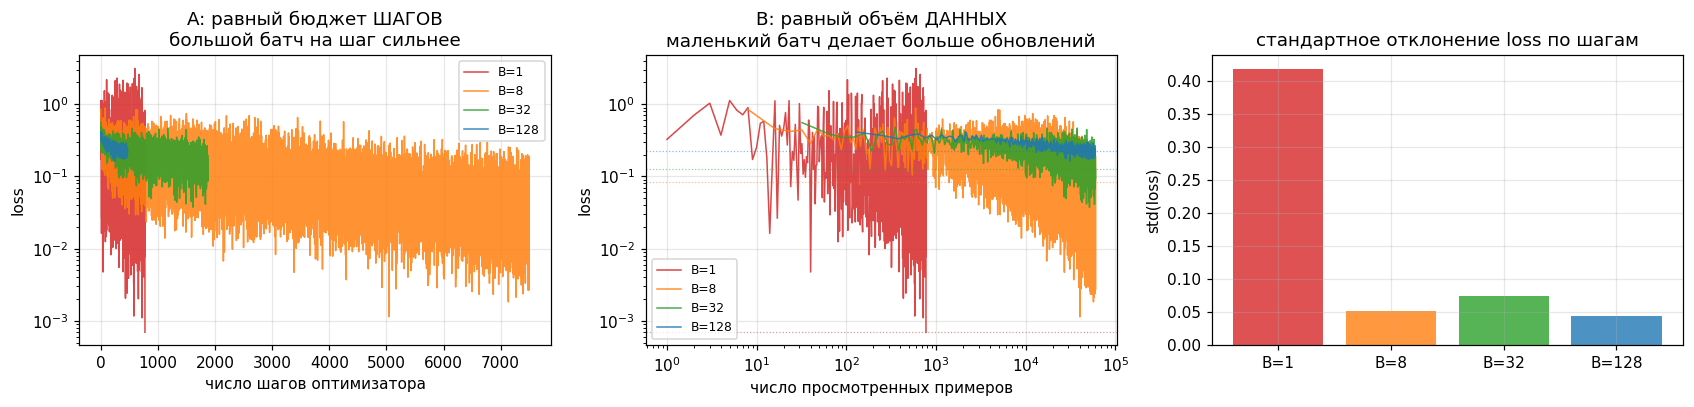

In [20]:
def train_batch_track(X, y, batch_size, total_examples=60000, lr=0.03, seed=0, H=16):
    '''Учит сеть, записывая loss при каждом шаге; помним и шаг, и число примеров.'''
    r = np.random.default_rng(seed)
    net = build_net(X.shape[1], H, 2, seed=seed)
    steps = max(total_examples // batch_size, 1)
    full = r.permutation(len(X)); cursor = 0
    rec = {'step': [], 'samples': [], 'loss': []}
    for t in range(steps):
        if cursor + batch_size > len(X):
            full = r.permutation(len(X)); cursor = 0
        b = full[cursor:cursor + batch_size]; cursor += batch_size
        logits = net.forward(X[b])
        sce = SoftmaxCrossEntropy()
        loss = sce.forward(logits, y[b])
        net.zero_grad(); net.backward(sce.backward()); net.sgd_step(lr)
        rec['step'].append(t + 1); rec['samples'].append((t + 1) * batch_size); rec['loss'].append(loss)
        if loss < 1e-3:
            break
    set_train(net, False)
    return net, rec


batch_sizes = [1, 8, 32, 128]
colors = dict(zip(batch_sizes, ['tab:red', 'tab:orange', 'tab:green', 'tab:blue']))
runs = {}
for bs in batch_sizes:
    net, rec = train_batch_track(Xtr, ytr, bs, total_examples=60000, lr=0.03, seed=0)
    runs[bs] = (net, rec)
    print(f'B={bs:>3}: шагов={len(rec["step"]):>5}  примеров={rec["samples"][-1]:>6}  '
          f'финальный loss={rec["loss"][-1]:.3f}  test_acc={accuracy(net, Xte, yte):.3f}')

fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.8))
for bs in batch_sizes:
    net, rec = runs[bs]
    axes[0].plot(rec['step'], rec['loss'], c=colors[bs], lw=1, alpha=0.85, label=f'B={bs}')
    axes[1].plot(rec['samples'], rec['loss'], c=colors[bs], lw=1, alpha=0.85, label=f'B={bs}')
    axes[1].axhline(rec['loss'][-1], c=colors[bs], ls=':', lw=0.8, alpha=0.5)
axes[0].set_xlabel('число шагов оптимизатора'); axes[0].set_ylabel('loss')
axes[0].set_title('A: равный бюджет ШАГОВ\nбольшой батч на шаг сильнее')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3); axes[0].set_yscale('log')
axes[1].set_xlabel('число просмотренных примеров'); axes[1].set_ylabel('loss')
axes[1].set_title('B: равный объём ДАННЫХ\nмаленький батч делает больше обновлений')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3); axes[1].set_xscale('log'); axes[1].set_yscale('log')

# насколько шумит loss по шагам при фиксированном B
axes[2].set_title('стандартное отклонение loss по шагам')
stds = [np.std(runs[bs][1]['loss'][-2000:]) for bs in batch_sizes]
axes[2].bar([f'B={bs}' for bs in batch_sizes], stds, color=[colors[bs] for bs in batch_sizes], alpha=0.8)
axes[2].set_ylabel('std(loss)'); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Вывод двух графиков — ровно про компромисс из раздела 3.3:

- **слева** (равное число шагов): большой батч сходится «дешевле» — меньше шагов на тот же loss;
- **в центре** (равный объём данных): при одинаковом числе просмотренных примеров маленький батч успевает сделать в разы больше обновлений и часто обгоняет — то есть он **эффективнее по данным**;
- **справа**: шум шага монотонно падает с ростом $B$.

Поэтому практический выбор — компромисс: маленький батч → больше обновлений на просмотренный пример, но шумнее и хуже укладывается в железо; большой → эффективнее на шаг, но требует большего lr и данных, чтобы дать то же число обновлений.

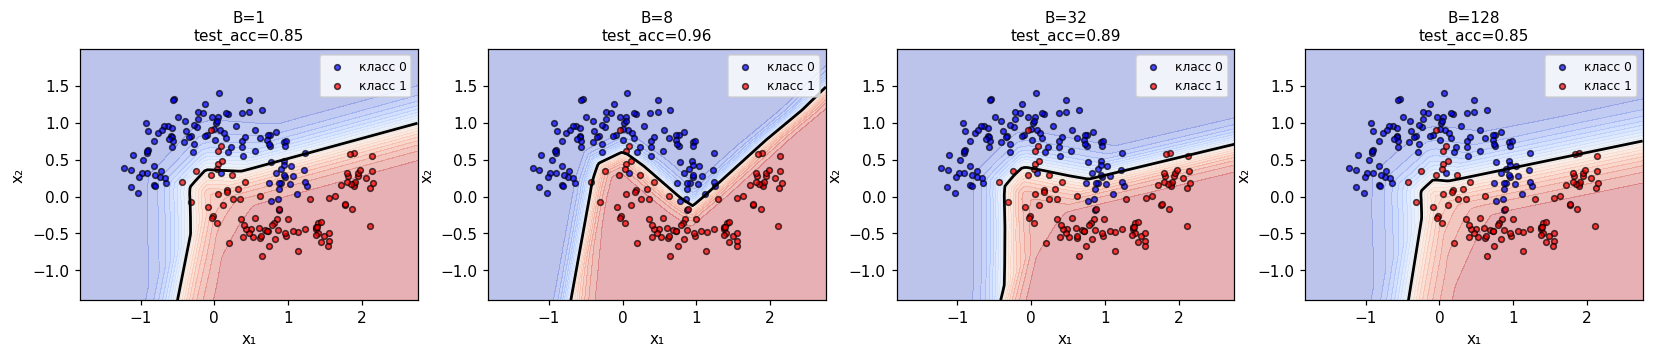

In [21]:
# границы решений: какой батч что выучил к концу обучения
fig, axes = plt.subplots(1, len(batch_sizes), figsize=(15, 3.3))
for ax, bs in zip(axes, batch_sizes):
    net, rec = runs[bs]
    plot_decision(ax, Xte, yte, net, title=f'B={bs}\ntest_acc={accuracy(net, Xte, yte):.2f}')
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
plt.tight_layout(); plt.show()

### 3.6. Шум градиента: измеряем

Проверим теорию $\text{шум}\sim\sigma/\sqrt{B}$ напрямую: зафиксируем параметры сети на инициализации, посчитаем **точный** (полный) градиент и сравним с ним градиенты случайных батчей размера $B$.

$$\text{относительная ошибка}(B) = \frac{\|\hat g_B - g_{full}\|_2}{\|g_{full}\|_2}$$

Если построить это в лог-лог осях, должна получиться прямая с наклоном $-1/2$: удвоение батча уменьшает шум примерно в $\sqrt2$ раз.

размерность вектора градиента: 82


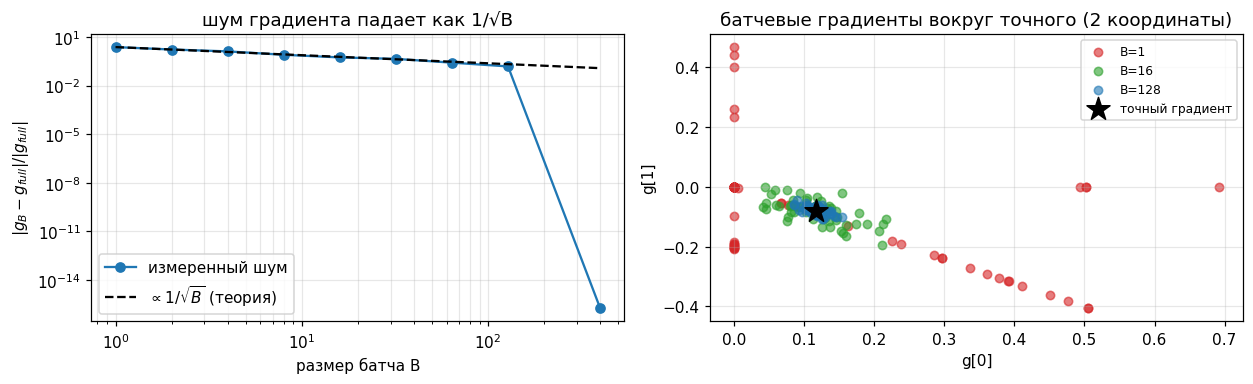

Наклон на левом графике ≈ −0.5 — теория подтверждена.


In [22]:
def flat_grad(X, y, net):
    '''Собирает градиент loss по всем параметрам сети в один вектор.'''
    set_train(net, True)
    net.zero_grad()
    sce = SoftmaxCrossEntropy()
    logits = net.forward(X)
    sce.forward(logits, y)
    net.backward(sce.backward())
    return np.concatenate([g.ravel().copy() for _, _, g in net.params()])


r = np.random.default_rng(1)
probe_net = build_net(2, 16, 2, seed=7)
g_full = flat_grad(Xtr, ytr, probe_net)
print('размерность вектора градиента:', g_full.shape[0])

bs_list = [1, 2, 4, 8, 16, 32, 64, 128, 400]
noise, theory = [], []
for B in bs_list:
    errs = []
    for _ in range(25):
        idx = r.choice(len(Xtr), size=B, replace=False)
        gB = flat_grad(Xtr[idx], ytr[idx], probe_net)
        errs.append(np.linalg.norm(gB - g_full) / np.linalg.norm(g_full))
    noise.append(np.mean(errs))
noise = np.array(noise)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
axes[0].loglog(bs_list, noise, 'o-', label='измеренный шум')
ref = noise[0] / np.sqrt(np.array(bs_list))
axes[0].loglog(bs_list, ref, 'k--', label=r'$\propto 1/\sqrt{B}$ (теория)')
axes[0].set_xlabel('размер батча B'); axes[0].set_ylabel(r'$\|g_B - g_{full}\| / \|g_{full}\|$')
axes[0].set_title('шум градиента падает как 1/√B'); axes[0].legend(); axes[0].grid(alpha=0.3, which='both')

# как отдельные батчевые градиенты "размазаны" вокруг точного: первые две координаты
axes[1].set_title('батчевые градиенты вокруг точного (2 координаты)')
for B, c in [(1, 'tab:red'), (16, 'tab:green'), (128, 'tab:blue')]:
    pts = []
    for _ in range(60):
        idx = r.choice(len(Xtr), size=B, replace=False)
        pts.append(flat_grad(Xtr[idx], ytr[idx], probe_net)[:2])
    pts = np.array(pts)
    axes[1].scatter(pts[:, 0], pts[:, 1], s=30, alpha=0.6, color=c, label=f'B={B}')
axes[1].scatter([g_full[0]], [g_full[1]], marker='*', s=250, c='k', zorder=5, label='точный градиент')
axes[1].set_xlabel('g[0]'); axes[1].set_ylabel('g[1]'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('Наклон на левом графике ≈ −0.5 — теория подтверждена.')

## 3.7. Интерактив: батч и learning rate

Покрутите размер батча и lr. Обратите внимание: маленький батч требует **меньшего** lr (иначе разброс уводит оптимизатор), а большой — выдерживает большой lr. Это и есть «правило линейного масштабирования» на практике.

In [23]:
def batch_lr_probe(batch_size=32, lr=0.1, epochs=25):
    net, hist = train_classifier(Xtr, ytr, Xte, yte, H=16, batch_size=batch_size,
                                 lr=lr, epochs=epochs, seed=0, steps_per_epoch=50)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(hist['step_loss'], lw=0.9, alpha=0.6, label='loss по шагам')
    axes[0].plot(np.arange(len(hist['epoch_loss'])) * 50, hist['epoch_loss'],
                 'r-', lw=2, label='loss по эпохам')
    axes[0].set_yscale('log'); axes[0].set_xlabel('шаг'); axes[0].set_ylabel('loss (log)')
    axes[0].set_title(f'B={batch_size}, lr={lr}'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
    plot_decision(axes[1], Xte, yte, net, title=f'test_acc={hist["val_acc"][-1]:.2f}')
    axes[1].set_xlabel('x₁'); axes[1].set_ylabel('x₂')
    plt.tight_layout(); plt.show()


display(widgets.interact(batch_lr_probe,
        batch_size=widgets.SelectionSlider(options=[1, 4, 8, 16, 32, 64, 128, 256, 400], value=32, description='batch'),
        lr=widgets.FloatSlider(value=0.1, min=0.001, max=1.0, step=0.001, description='lr', readout_format='.3f'),
        epochs=widgets.IntSlider(value=25, min=10, max=60, step=5, description='эпох')))

interactive(children=(SelectionSlider(description='batch', index=4, options=(1, 4, 8, 16, 32, 64, 128, 256, 40…

<function __main__.batch_lr_probe(batch_size=32, lr=0.1, epochs=25)>

## 3.8. Итог по части 3

- Точный градиент = среднее градиентов по примерам; мини-батч даёт **несмещённую** оценку.
- Батч нужен ради: (1) скорости шага, (2) векторного/GPU-параллелизма, (3) управляемой статистики шага.
- Шум оценки $\sim 1/\sqrt{B}$: маленький батч шумнее, но делает больше шагов и нередко обобщает лучше; большой — глаже, но требует большего lr и эпох.
- При росте $B$ в $k$ раз lr обычно масштабируют пропорционально.

---
# Часть 4. Инициализация весов

## 4.1. Почему нулями (и вообще одинаково) — плохо

Возьмём сеть, где все веса и bias инициализированы нулями, и посмотрим, что произойдёт с двумя нейронами скрытого слоя.

**Симметрия.** В forward-проходе все нейроны одного слоя получают одинаковый вход и одинаковые веса, значит выдают **одинаковые активации**:

$$z_1 = z_2 = \dots = z_H, \qquad a_1 = a_2 = \dots = a_H$$

**Симметрия не ломается и в backward.** У всех нейронов одинаковый локальный градиент, значит одинаковые $dW$-строки:

$$\frac{\partial J}{\partial w_{1}} = \frac{\partial J}{\partial w_{2}} = \dots = \frac{\partial J}{\partial w_{H}}$$

После шага обновления веса **снова останутся равными**. Сеть из $H$ нейронов навсегда эквивалентна сети из **одного** нейрона: она физически не может выучить разные признаки. Это называется **проблемой симметрии** (symmetry breaking problem).

Строгий аргумент: для любого входа $x$ и любой перестановки $\pi$ нейронов скрытого слоя значения forward-прохода одинаковы (перестановочная симметрия функции). Градиент нулевой инициализации лежит в «симметричном» подпространстве и никогда из него не выходит.

**Что нужно:** разные веса у разных нейронов. Проще всего — **случайная** инициализация. Но «просто случайная» — тоже ловушка: слишком большие или слишком маленькие значения ломают обучение (масштаб!).

W1 (zeros init) после 20 эпох — первые 3 столбца:
[[0. 0. 0.]
 [0. 0. 0.]]
все столбцы одинаковы: True
эффективная размерность скрытого слоя (rank W1): 0 из 16
train_acc при zeros-init: 0.500  (сеть = один нейрон)
train_acc при He-init   : 0.993
строки активации скрытого слоя одинаковы: True  (все нейроны считают одно и то же)
std по нейронам (должен быть ~0): 0.0


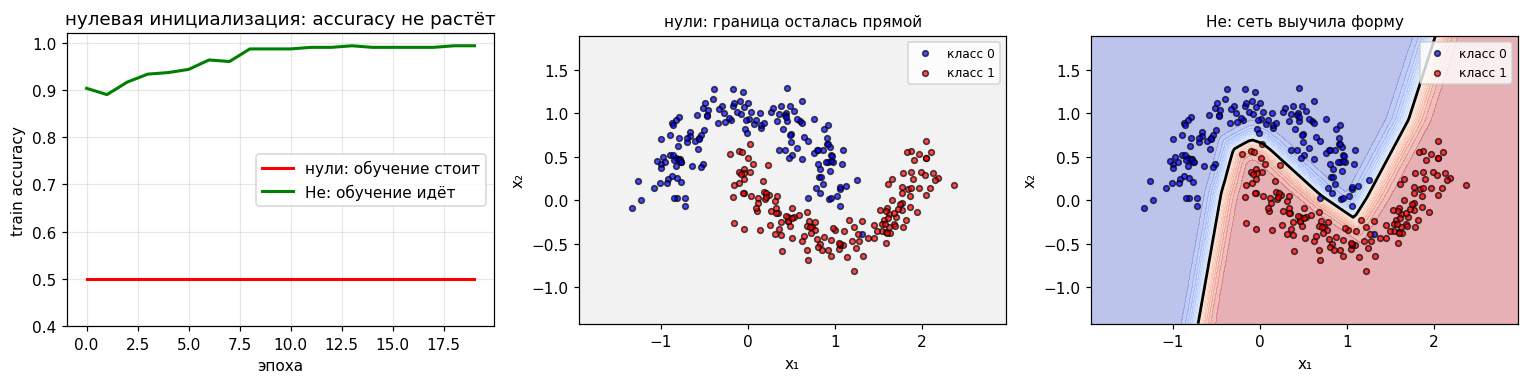

In [24]:
# Демонстрация: сеть с нулевой инициализацией не учится
Xs, ys = make_moons(300, noise=0.15, seed=3)

net_zeros, hist_zeros = train_classifier(Xs, ys, Xs, ys, H=16, batch_size=32, lr=0.3,
                                         epochs=20, seed=0, init='zeros', verbose=False)
net_he, hist_he = train_classifier(Xs, ys, Xs, ys, H=16, batch_size=32, lr=0.3,
                                   epochs=20, seed=0, init='he')

# проверим симметрию: все столбцы W1 одинаковы?
W1z = net_zeros.layers[0].W
print('W1 (zeros init) после 20 эпох — первые 3 столбца:')
print(np.round(W1z[:, :3], 4))
print('все столбцы одинаковы:', np.allclose(W1z[:, 0], W1z[:, 1]) and np.allclose(W1z[:, 1], W1z[:, 2]))
print('эффективная размерность скрытого слоя (rank W1):',
      np.linalg.matrix_rank(W1z), 'из', W1z.shape[1])
print(f'train_acc при zeros-init: {hist_zeros["train_acc"][-1]:.3f}  (сеть = один нейрон)')
print(f'train_acc при He-init   : {hist_he["train_acc"][-1]:.3f}')

# ВАЖНО: при нулевой инициализации выход W1 НЕ равен нулю - bias всё сдвигает.
# Покажем важную деталь: если bias тоже занулить, все активации буквально одинаковые.
set_train(net_zeros, False)
A1 = net_zeros.layers[0].forward(Xs)
A1_relu = np.maximum(0, A1)
print('строки активации скрытого слоя одинаковы:',
      np.allclose(A1_relu[:, 0], A1_relu[:, 1]), ' (все нейроны считают одно и то же)')
print('std по нейронам (должен быть ~0):', float(A1_relu.std(axis=1).mean()))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(hist_zeros['train_acc'], 'r-', lw=2, label='нули: обучение стоит')
axes[0].plot(hist_he['train_acc'], 'g-', lw=2, label='He: обучение идёт')
axes[0].set_xlabel('эпоха'); axes[0].set_ylabel('train accuracy')
axes[0].set_ylim(0.4, 1.02)
axes[0].set_title('нулевая инициализация: accuracy не растёт'); axes[0].legend(); axes[0].grid(alpha=0.3)

plot_decision(axes[1], Xs, ys, net_zeros, title='нули: граница осталась прямой')
axes[1].set_xlabel('x₁'); axes[1].set_ylabel('x₂')
plot_decision(axes[2], Xs, ys, net_he, title='He: сеть выучила форму')
axes[2].set_xlabel('x₁'); axes[2].set_ylabel('x₂')
plt.tight_layout(); plt.show()

### 4.1.1. Геометрия: как нули «схлопывают» сеть

Посмотрим прямо на веса. При нулевой инициализации все нейроны скрытого слоя — клоны. Нарисуем для маленькой сети матрицу весов $W_1$ как картинку: при нулях все строки/столбцы одинаковые, при случайной — разные.

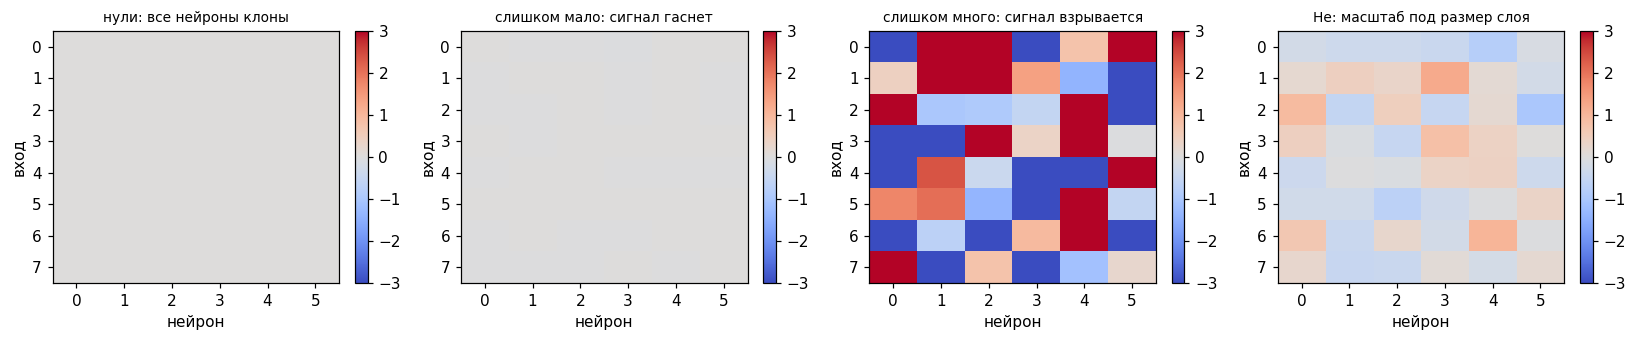

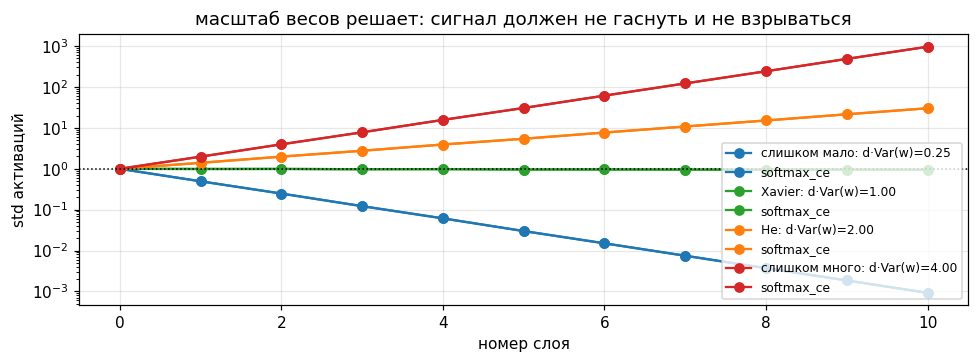

In [25]:
r = np.random.default_rng(2)
d_in, H = 8, 6

W_zeros = np.zeros((d_in, H))
W_small = r.normal(0, 0.01, size=(d_in, H))       # слишком маленькие
W_large = r.normal(0, 5.0, size=(d_in, H))        # слишком большие
W_he = r.normal(0, np.sqrt(2 / d_in), size=(d_in, H))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, W, t in zip(axes, [W_zeros, W_small, W_large, W_he],
                    ['нули: все нейроны клоны', 'слишком мало: сигнал гаснет',
                     'слишком много: сигнал взрывается', 'He: масштаб под размер слоя']):
    im = ax.imshow(W, cmap='coolwarm', aspect='auto', vmin=-3, vmax=3)
    ax.set_title(t, fontsize=9); ax.set_xlabel('нейрон'); ax.set_ylabel('вход')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# прохождение сигнала через 10 линейных слоёв при разном масштабе: Var(z) = d·Var(w)·Var(x)
def signal_through(W_scale, n_layers=10, n=300, seed=0):
    rr = np.random.default_rng(seed)
    x = rr.normal(size=(n, 64))
    stds = [x.std()]
    for _ in range(n_layers):
        W = rr.normal(0, W_scale, size=(64, 64))
        x = x @ W
        stds.append(x.std())
    return np.array(stds)

d = 64
scales_info = [(0.5 / np.sqrt(d), 'tab:blue', 'слишком мало'),
               (1 / np.sqrt(d), 'tab:green', 'Xavier'),
               (np.sqrt(2 / d), 'tab:orange', 'He'),
               (2 / np.sqrt(d), 'tab:red', 'слишком много')]
fig, ax = plt.subplots(figsize=(9, 3.4))
for sc, c, name in scales_info:
    ax.plot(signal_through(sc), 'o-', color=c, label=f'{name}: d·Var(w)={d*sc*sc:.2f}')
    ax.plot(signal_through(sc), 'o-', color=c, label=lab)
ax.axhline(1.0, color='k', ls=':', lw=1)
ax.set_xlabel('номер слоя'); ax.set_ylabel('std активаций')
ax.set_title('масштаб весов решает: сигнал должен не гаснуть и не взрываться')
ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_yscale('log')
plt.tight_layout(); plt.show()

## 4.2. Сколько должен быть масштаб весов: variance-preserving

Рассуждение «на пальцах», которое приводит к Xavier/He. Пусть на входе $d$ чисел $x_k$ независимы, с нулевым средним и дисперсией $\mathrm{Var}(x)$, а веса $w_k$ независимы, с нулевым средним и дисперсией $\mathrm{Var}(w)$. Тогда

$$z = \sum_{k=1}^{d} w_k x_k
\quad\Longrightarrow\quad
\mathrm{Var}(z) = \sum_{k=1}^{d}\mathrm{Var}(w_k x_k) = d\,\mathrm{Var}(w)\,\mathrm{Var}(x)$$

Чтобы дисперсия **сохранялась через слой** ($\mathrm{Var}(z)\approx\mathrm{Var}(x)$), нужно $d\,\mathrm{Var}(w)\approx 1$, то есть

$$\boxed{\ \mathrm{Var}(w) = \frac{1}{d}\ }\qquad\text{(Xavier/Glorot, для } \tanh/\text{sigmoid)}$$

Учитывая, что у activation $\tanh$ производная $\approx 1$ около нуля, этого достаточно для «линейного» режима. Для **ReLU** половина нейронов обнуляется: $a = \max(0,z)$ имеет $\mathrm{Var}(a)\approx \tfrac12\mathrm{Var}(z)$. Чтобы компенсировать потерю масштаба вперёд, нужен множитель $2$:

$$\boxed{\ \mathrm{Var}(w) = \frac{2}{d}\ }\qquad\text{(He/Kaiming, для ReLU)}$$

На практике берут $W \sim \mathcal{N}\bigl(0,\tfrac{2}{d_{in}}\bigr)$ (He) или $\mathcal{N}\bigl(0,\tfrac{1}{d_{in}}\bigr)$ (Xavier). Bias инициализируют нулями — симметрию они не восстанавливают, потому что веса уже разные.

**Помимо нулей бывает ещё хуже:** константа $c\ne0$ даёт ту же самую симметрию (все нейроны клоны); слишком маленький масштаб — градиенты гаснут; слишком большой — сигнал взрывается (см. график выше).

## 4.3. Таблица стандартных инициализаций

| Инициализация | Формула | Для чего |
|---|---|---|
| **Zeros / const** | $W = 0$ | ❌ Никогда. Симметрия не ломается |
| **Random normal** | $W\sim\mathcal{N}(0, 0.01^2)$ | ⚠️ Простейшая; масштаб не подстраивается под размер слоя |
| **Xavier / Glorot** | $W\sim\mathcal{N}\!\left(0, \frac{1}{d_{in}}\right)$ | ✅ Для $\tanh$, sigmoid |
| **He / Kaiming** | $W\sim\mathcal{N}\!\left(0, \frac{2}{d_{in}}\right)$ | ✅ Для ReLU и её вариантов |
| **Uniform-варианты** | $W\sim U[-\sqrt{6/(d_{in}+d_{out})}, +\dots]$ | ✅ Вариант Xavier/He |

В PyTorch это буквально `nn.init.kaiming_normal_` и `nn.init.xavier_uniform_`. Правило: **инициализация должна зависеть от размера слоя.**

## 4.4. Эксперимент: инициализация задаёт судьбу обучения

Прогоним одну и ту же сеть 2→64→64→2 с разными инициализациями и посмотрим на кривые loss и на распределение активаций первого скрытого слоя.

Чтобы наглядно показать эффект масштаба на многослойной сети, используем глубокую сеть с `tanh` (ReLU с слишком большими весами просто даст много мёртвых нейронов).

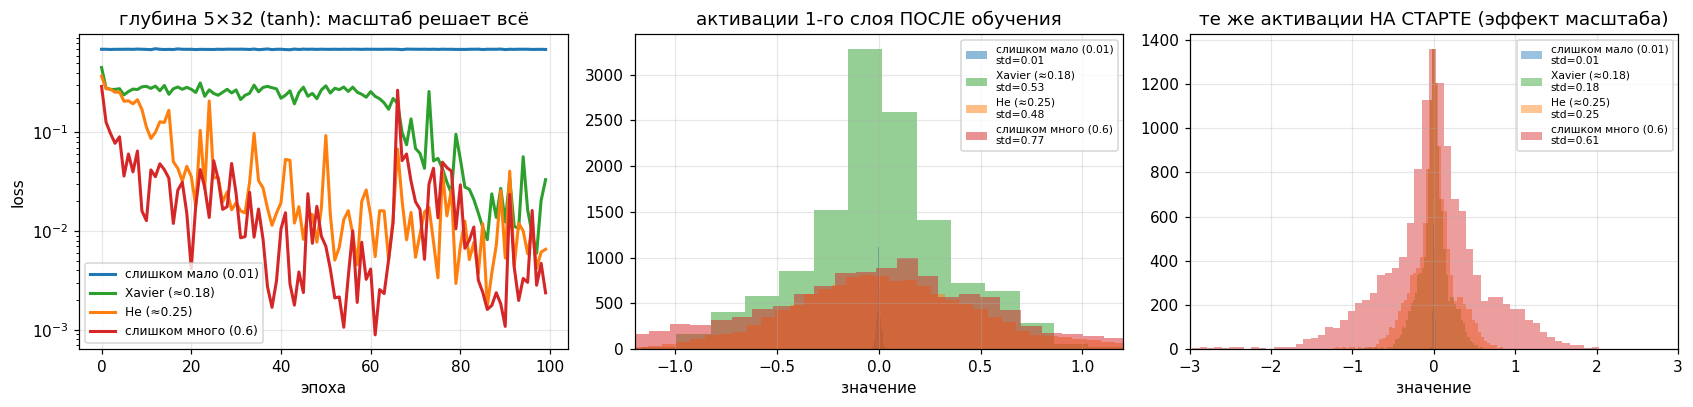

На старте масштаб задаёт «ширину» активаций (std): слишком мало — сигнал почти 0.
В кривых loss главное видно сразу: при слишком малом масштабе сеть вообще не обучается;
остальные сходятся, но большой масштаб даёт менее стабильные кривые.


In [26]:
def deep_net(seed, scale, n_layers=5, width=32, d_in=2):
    '''Глубокая сеть tanh с заданным масштабом весов (для наглядности эффекта).'''
    r = np.random.default_rng(seed)
    layers, d = [], d_in
    for _ in range(n_layers):
        lin = Linear(d, width, init='xavier', seed=seed)
        lin.W = r.normal(0, scale, size=(d, width))    # переопределяем масштаб вручную
        layers += [lin, Tanh()]
        d = width
    layers.append(Linear(d, 2, init='xavier', seed=seed))
    return Sequential(*layers)


class Tanh(Layer):
    def forward(self, z):
        self.t = np.tanh(z)
        return self.t

    def backward(self, dA):
        return dA * (1 - self.t ** 2)


def train_deep(scale, seed=0, epochs=60, lr=0.15, batch_size=32):
    net = deep_net(seed, scale)
    r = np.random.default_rng(seed)
    hist = []
    for ep in range(epochs):
        ep_loss, nb = 0.0, 0
        for s in range(0, len(Xtr), batch_size):
            idx = r.permutation(len(Xtr))[s:s + batch_size]
            logits = net.forward(Xtr[idx])
            sce = SoftmaxCrossEntropy(); loss = sce.forward(logits, ytr[idx])
            net.zero_grad(); net.backward(sce.backward()); net.sgd_step(lr)
            ep_loss += loss * len(idx); nb += len(idx)
        hist.append(ep_loss / nb)
    return net, np.array(hist)


scales = {'слишком мало (0.01)': 0.01,
          'Xavier (≈0.18)': np.sqrt(1 / 32),
          'He (≈0.25)': np.sqrt(2 / 32),
          'слишком много (0.6)': 0.6}
fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.8))
nets = {}
for (name, sc), c in zip(scales.items(), ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']):
    net, hist = train_deep(sc, epochs=100)
    nets[name] = net
    axes[0].plot(hist, c=c, lw=2, label=name)
axes[0].set_yscale('log'); axes[0].set_xlabel('эпоха'); axes[0].set_ylabel('loss')
axes[0].set_title('глубина 5×32 (tanh): масштаб решает всё'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

# распределение активаций ПЕРВОГО скрытого слоя
for (name, sc), c in zip(scales.items(), ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']):
    set_train(nets[name], False)
    a1 = nets[name].layers[0].forward(Xtr)
    axes[1].hist(a1.ravel(), bins=60, alpha=0.5, color=c, label=f'{name}\nstd={a1.std():.2f}')
axes[1].set_title('активации 1-го слоя ПОСЛЕ обучения'); axes[1].set_xlabel('значение')
axes[1].set_xlim(-1.2, 1.2)
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)

# то же, но СРАЗУ ПОСЛЕ инициализации: чистый эффект масштаба
for (name, sc), c in zip(scales.items(), ['tab:blue', 'tab:green', 'tab:orange', 'tab:red']):
    lin = Linear(2, 32, seed=0); lin.W = np.random.default_rng(0).normal(0, sc, size=(2, 32))
    a1 = lin.forward(Xtr)
    axes[2].hist(a1.ravel(), bins=60, alpha=0.45, color=c, label=f'{name}\nstd={a1.std():.2f}')
axes[2].set_title('те же активации НА СТАРТЕ (эффект масштаба)'); axes[2].set_xlabel('значение')
axes[2].set_xlim(-3, 3)
axes[2].legend(fontsize=7); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('На старте масштаб задаёт «ширину» активаций (std): слишком мало — сигнал почти 0.')
print('В кривых loss главное видно сразу: при слишком малом масштабе сеть вообще не обучается;')
print('остальные сходятся, но большой масштаб даёт менее стабильные кривые.')

### 4.5. Активации и глубина: «мёртвые» нейроны и исчезающий сигнал

Ещё один аспект — **activation**. Три классические картинки:

- sigmoid/tanh: хвосты почти плоские → глубокие стеки гаснут;
- ReLU: фиксирует проблему насыщения, но нейрон умирает, если его $z$ стало $\le 0$ на всех примерах;
- инициализация подбирается **под activation**: He для ReLU, Xavier для tanh.

Слева — формы трёх функций активации. В центре — реальный эффект «умирающего ReLU»: при слишком большом learning rate веса уезжают в минус, и часть нейронов гаснет **навсегда** (их $z \le 0$ на всём батче, градиент равен нулю, восстановиться они уже не могут). Справа — распределение активаций на глубине: с He-масштабом оно стабильное, а с большими весами «взрывается».

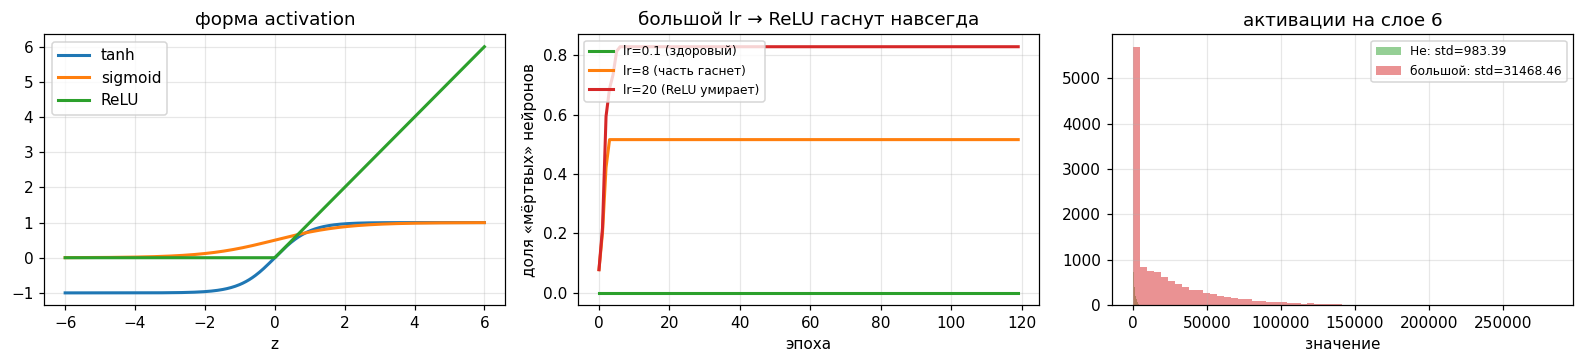

In [27]:
r = np.random.default_rng(5)
zline = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.4))
axes[0].plot(zline, np.tanh(zline), lw=2, label='tanh')
axes[0].plot(zline, 1/(1+np.exp(-zline)), lw=2, label='sigmoid')
axes[0].plot(zline, np.maximum(0, zline), lw=2, label='ReLU')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title('форма activation'); axes[0].set_xlabel('z')

# «умирающий» ReLU: слишком большой lr гонит веса в минус и нейроны гаснут навсегда
Xdy, ydy = make_moons(400, noise=0.2, seed=7)

def dead_relu_frac(lr, epochs=120, H=64, seed=1):
    '''тренируем ReLU-сеть с заданным lr и считаем долю нейронов, у которых
    z <= 0 НА ВСЕХ примерах (такие нейроны получают нулевой градиент и мертвы).'''
    r = np.random.default_rng(seed)
    W1 = r.normal(0, np.sqrt(2/2), size=(2, H)); b1 = np.zeros(H)
    W2 = r.normal(0, np.sqrt(2/H), size=(H, 2)); b2 = np.zeros(2)
    n = len(Xdy); frac = []
    for _ in range(epochs):
        z1 = Xdy @ W1 + b1
        a1 = np.maximum(0, z1)
        z2 = a1 @ W2 + b2
        e = np.exp(z2 - z2.max(1, keepdims=True)); p = e / e.sum(1, keepdims=True)
        dz2 = (p - np.eye(2)[ydy]) / n
        dW2 = a1.T @ dz2; db2 = dz2.sum(0)
        da1 = dz2 @ W2.T; dz1 = da1 * (z1 > 0)
        dW1 = Xdy.T @ dz1; db1 = dz1.sum(0)
        W1 -= lr*dW1; b1 -= lr*db1; W2 -= lr*dW2; b2 -= lr*db2
        frac.append(((Xdy @ W1 + b1) <= 0).all(axis=0).mean())
    return np.array(frac)

for lr, c, lab in [(0.1, 'tab:green', 'lr=0.1 (здоровый)'),
                   (8.0, 'tab:orange', 'lr=8 (часть гаснет)'),
                   (20.0, 'tab:red', 'lr=20 (ReLU умирает)')]:
    f = dead_relu_frac(lr)
    axes[1].plot(f, color=c, lw=2, label=lab)
axes[1].set_xlabel('эпоха'); axes[1].set_ylabel('доля «мёртвых» нейронов')
axes[1].set_title('большой lr → ReLU гаснут навсегда'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

# распределение активаций на глубине 5 при He vs слишком большом масштабе
for sc, c, lab in [(np.sqrt(2/2), 'tab:green', 'He'), (2.0, 'tab:red', 'большой')]:
    rr = np.random.default_rng(0); x = rr.normal(size=(200, 2))
    for _ in range(5):
        W = rr.normal(0, sc, size=(x.shape[1], 64))
        x = np.maximum(0, x @ W)
    axes[2].hist(x.ravel(), bins=60, alpha=0.5, color=c, label=f'{lab}: std={x.std():.2f}')
axes[2].set_title('активации на слое 6'); axes[2].set_xlabel('значение'); axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4.6. Итог по части 4

- Инициализация нулями (и любой **одинаковой**) не ломает симметрию: все нейроны слоя навсегда остаются клонами.
- Нужна случайная, но с **правильным масштабом**: $\mathrm{Var}(w)=1/d_{in}$ (Xavier) или $2/d_{in}$ (He).
- Слишком малый масштаб — сигнал и градиент гаснут; слишком большой — взрыв или мёртвые ReLU.
- Правило: **инициализация зависит от типа activation и размера слоя**.

---
# Часть 5. Регуляризация

## 5.1. Зачем она нужна: underfit — goodfit — overfit

Сеть достаточно большого размера может **запомнить** обучающую выборку, включая её шум, и при этом плохо работать на новых данных. Это **переобучение (overfitting)**.

Три режима:

- **underfit** — модель слишком простая: плоха и на train, и на test (высокий bias);
- **good fit** — ловит закономерность, а не шум;
- **overfit** — отличный train, плохой test (высокая variance).

Классическая картинка про полиномы: степень 1 — underfit, степень 4 — хорошо, степень 15 — проходит через все точки и дико колеблется между ними.

![Полиномы разных степеней: недообучение, хорошая подгонка, переобучение](https://upload.wikimedia.org/wikipedia/commons/thumb/1/19/Overfitting.svg/960px-Overfitting.svg.png)

*Внешняя картинка: [Overfitting](https://commons.wikimedia.org/wiki/File:Overfitting.svg), Wikimedia Commons.*

**Регуляризация** — это любой приём, который мешает модели подстроиться под шум, то есть **сужает пространство решений** и улучшает обобщение.

![Компромисс bias–variance: суммарная ошибка минимальна при средней сложности модели](https://upload.wikimedia.org/wikipedia/commons/thumb/6/63/Bias-variance-tradeoff.png/960px-Bias-variance-tradeoff.png)

*Внешняя картинка: [Bias-variance-tradeoff](https://commons.wikimedia.org/wiki/File:Bias-variance-tradeoff.png), Wikimedia Commons.*

## 5.2. L2-регуляризация (weight decay)

Самый простой способ наказать модель за излишнюю сложность — добавить к loss штраф на **величину весов**:

$$J_{\text{reg}}(\theta) = J(\theta) + \frac{\lambda}{2}\sum_{\ell}\|W_\ell\|_2^2
= J(\theta) + \frac{\lambda}{2}\sum_\ell \sum_{k,j} w_{kj}^2$$

где $\lambda>0$ — сила регуляризации. Градиент штрафа линеен по весу:

$$\frac{\partial}{\partial w}\Bigl(\frac{\lambda}{2}w^2\Bigr) = \lambda w
\qquad\Longrightarrow\qquad
\boxed{\,dW \mathrel{+}= \lambda W\,}$$

то есть к обычному градиенту просто добавляется $\lambda W$. На шаге обновления это выглядит как

$$w \leftarrow w - \eta\,(dW + \lambda w) = (1-\eta\lambda)\,w - \eta\, dW$$

множитель $(1-\eta\lambda)$ **«стягивает» веса к нулю** на каждом шаге — отсюда название **weight decay**. Большие веса получают большую обратную тягу; модель вынуждена объяснять данные «экономно».

**Почему это помогает:** большие веса → резкие, чувствительные функции → сильная реакция на шум. Штраф за норму делает функцию более гладкой (в пределе при очень большом $\lambda$ все веса → 0 и модель становится константой — это уже underfit).

Отметим: L2 иногда трактуют как Gaussian prior на веса в байесовской постановке ($P(w)\sim\mathcal{N}(0, \sigma^2)$) — тогда регуляризация = MAP-оценка, а не просто трюк.

## 5.3. L1-регуляризация

Вместо суммы квадратов можно штрафовать сумму **модулей**:

$$J_{\text{reg}} = J + \lambda\sum_{k,j}|w_{kj}|,
\qquad
\frac{\partial |w|}{\partial w} = \mathrm{sign}(w)
\qquad\Longrightarrow\qquad
\boxed{\,dW \mathrel{+}= \lambda\,\mathrm{sign}(W)\,}$$

Отличие принципиальное:

- **L2** «мягко» тянет все веса к нулю пропорционально их величине;
- **L1** сдвигает все веса на одинаковую величину $\lambda\eta$ — маленькие веса доходят до нуля и **застревают там**. Итог: **разреженные** решения (много нулевых весов), встроенный отбор признаков.

Поэтому L1 = Lasso, L2 = Ridge, а их смесь — ElasticNet.

![Сравнение L1/L2-регуляризации: L1 даёт угловатые решения с нулями, L2 — гладкое сжатие](https://upload.wikimedia.org/wikipedia/commons/thumb/0/02/Regularization.svg/960px-Regularization.svg.png)

*Внешняя картинка: [Regularization](https://commons.wikimedia.org/wiki/File:Regularization.svg), Wikimedia Commons.*

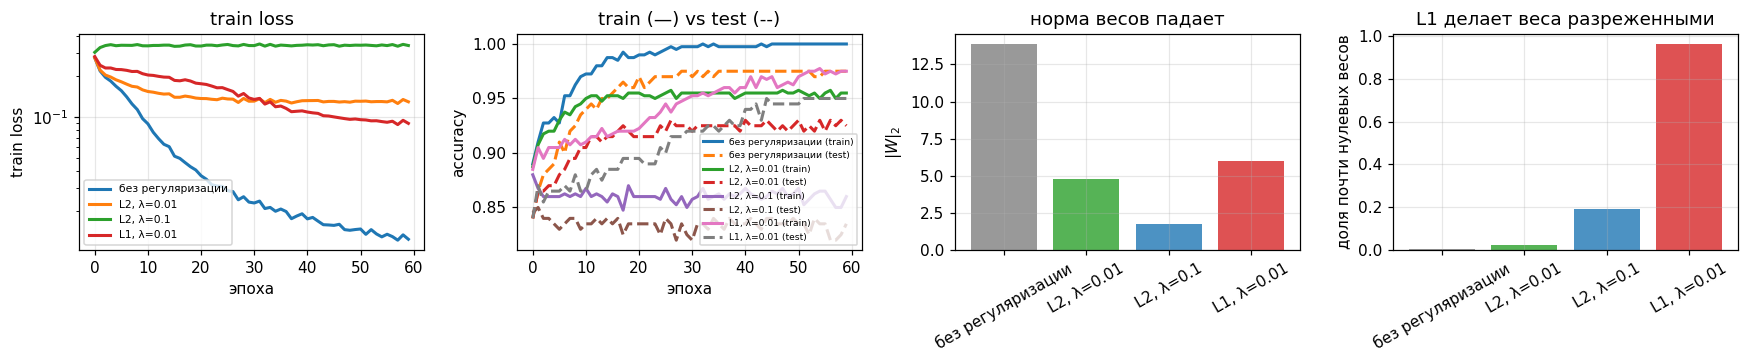

 без регуляризации: train_acc=1.000  test_acc=0.975
        L2, λ=0.01: train_acc=0.955  test_acc=0.925
         L2, λ=0.1: train_acc=0.860  test_acc=0.835
        L1, λ=0.01: train_acc=0.975  test_acc=0.950

Ключевое: L2 сжимает ВСЕ веса пропорционально их величине, L1 сдвигает все на
одинаковую величину, поэтому мелкие веса «доходят» до нуля и остаются там.


In [28]:
# Мини-эксперимент: L2 против L1 + как меняется норма и разреженность весов
runs_reg = {}
for reg, rtype, lab in [(0.0, 'l2', 'без регуляризации'),
                        (0.01, 'l2', 'L2, λ=0.01'),
                        (0.1, 'l2', 'L2, λ=0.1'),
                        (0.01, 'l1', 'L1, λ=0.01')]:
    net, hist = train_classifier(Xtr, ytr, Xte, yte, H=64, batch_size=32, lr=0.2,
                                 epochs=60, seed=0, reg=reg, reg_type=rtype)
    runs_reg[lab] = (net, hist)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
labs = list(runs_reg)
norms, sparsity = [], []
for lab in labs:
    net, hist = runs_reg[lab]
    norms.append(np.sqrt(sum(float((val ** 2).sum()) for name, val, _ in net.params() if name == 'W')))
    allW = np.concatenate([val.ravel() for name, val, _ in net.params() if name == 'W'])
    sparsity.append(float((np.abs(allW) < 0.01).mean()))
    axes[0].plot(hist['epoch_loss'], lw=2, label=lab)
    axes[1].plot(hist['train_acc'], lw=2, label=f'{lab} (train)')
    axes[1].plot(hist['val_acc'], lw=2, ls='--', label=f'{lab} (test)')
axes[0].set_xlabel('эпоха'); axes[0].set_ylabel('train loss'); axes[0].set_title('train loss')
axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3); axes[0].set_yscale('log')
axes[1].set_xlabel('эпоха'); axes[1].set_ylabel('accuracy'); axes[1].set_title('train (—) vs test (--)')
axes[1].legend(fontsize=6); axes[1].grid(alpha=0.3)
axes[2].bar(labs, norms, color=['gray', 'tab:green', 'tab:blue', 'tab:red'], alpha=0.8)
axes[2].set_ylabel(r'$\|W\|_2$'); axes[2].set_title('норма весов падает'); axes[2].tick_params(axis='x', rotation=30)
axes[3].bar(labs, sparsity, color=['gray', 'tab:green', 'tab:blue', 'tab:red'], alpha=0.8)
axes[3].set_ylabel('доля почти нулевых весов'); axes[3].set_title('L1 делает веса разреженными')
axes[3].tick_params(axis='x', rotation=30)
for ax in axes[2:]:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for lab in labs:
    net, hist = runs_reg[lab]
    print(f'{lab:>18}: train_acc={hist["train_acc"][-1]:.3f}  test_acc={hist["val_acc"][-1]:.3f}')
print()
print('Ключевое: L2 сжимает ВСЕ веса пропорционально их величине, L1 сдвигает все на')
print('одинаковую величину, поэтому мелкие веса «доходят» до нуля и остаются там.')

## 5.4. Гладкость решения: как L2 меняет границу

У большой сети без регуляризации граница решения может быть очень «изрезанной» — она огибает отдельные точки. L2 делает её глаже. Покажем это на маленькой выборке (так overfit заметнее).

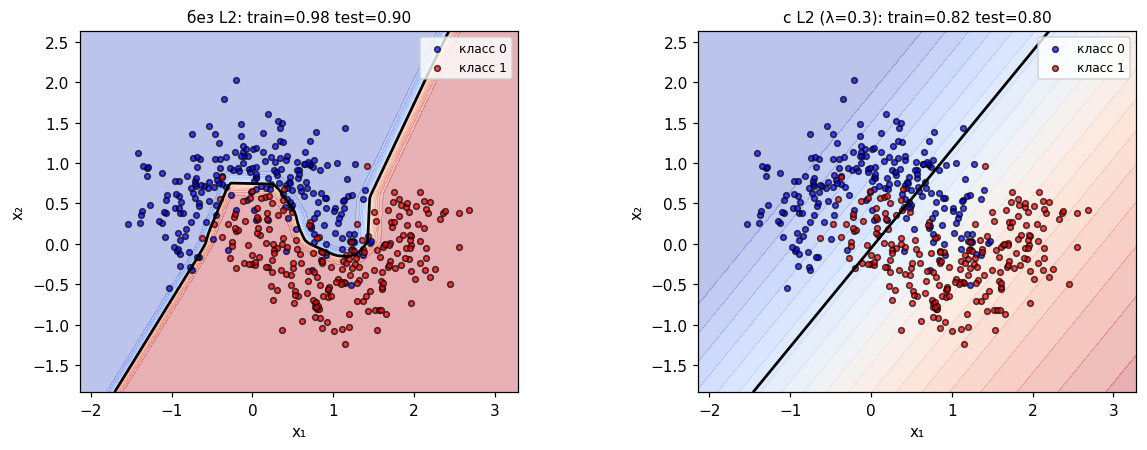

длина границы без L2: 486 клеток
длина границы с L2 : 454 клеток
При нулевой регуляризации граница длиннее и «рванее» - сеть огибает шумные точки.


In [29]:
# маленькая обучающая выборка (50 точек) против большой тестовой - видно переобучение
X_ov_all, y_ov_all = make_moons(500, noise=0.3, seed=11)
X_ov_tr, y_ov_tr, X_ov_te, y_ov_te = split(X_ov_all, y_ov_all, 50, seed=11)

net_noreg, hist_noreg = train_classifier(X_ov_tr, y_ov_tr, X_ov_te, y_ov_te, H=64,
                                         batch_size=16, lr=0.3, epochs=100, seed=0, reg=0.0)
net_reg, hist_reg = train_classifier(X_ov_tr, y_ov_tr, X_ov_te, y_ov_te, H=64,
                                     batch_size=16, lr=0.3, epochs=100, seed=0, reg=0.3)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
plot_decision(axes[0], X_ov_te, y_ov_te, net_noreg,
              title=f'без L2: train={hist_noreg["train_acc"][-1]:.2f} test={hist_noreg["val_acc"][-1]:.2f}')
plot_decision(axes[1], X_ov_te, y_ov_te, net_reg,
              title=f'с L2 (λ=0.3): train={hist_reg["train_acc"][-1]:.2f} test={hist_reg["val_acc"][-1]:.2f}')
for ax in axes:
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
plt.tight_layout(); plt.show()

# насколько изрезана граница: длина раздела по сетке (чем больше - тем более рваная)
def boundary_length(net, grid=250, span=4.5):
    xs = np.linspace(-span, span, grid)
    G1, G2 = np.meshgrid(xs, xs)
    set_train(net, False)
    P = (Softmax().forward(net.forward(np.c_[G1.ravel(), G2.ravel()]))[:, 1] > 0.5).reshape(G1.shape)
    return float((np.abs(np.diff(P, axis=0)).sum() + np.abs(np.diff(P, axis=1)).sum()))

print(f'длина границы без L2: {boundary_length(net_noreg):.0f} клеток')
print(f'длина границы с L2 : {boundary_length(net_reg):.0f} клеток')
print('При нулевой регуляризации граница длиннее и «рванее» - сеть огибает шумные точки.')

## 5.5. Dropout

Другой приём — **dropout**. На каждом шаге обучения мы случайно «выключаем» часть нейронов (с вероятностью $p$, обычно $p=0.2\ldots0.5$):

$$m_j \sim \mathrm{Bernoulli}(1-p), \qquad \tilde a_j = \frac{a_j\, m_j}{1-p}$$

Деление на $(1-p)$ — **inverted dropout**: сохраняет масштаб активаций, чтобы на тесте (когда dropout выключен) ничего менять не пришлось.

**Backward** тоже умножается на ту же маску:

$$\boxed{\,dA = \frac{d\tilde A \odot m}{1-p}\,}$$

**Зачем это работает:**

- сеть не может «положиться» на конкретный нейрон → учит **избыточные** представления;
- каждый шаг обучается случайная под-сеть (ансамбль!) — на тесте получается почти усреднение ансамбля;
- это сильная регуляризация, особенно для больших полносвязных слоёв.

**Ключевая деталь:** dropout активен **только во время обучения**. На инференсе маску не применяем (иначе предсказания станут случайными). Поэтому во всех фреймворках есть `model.train()` / `model.eval()` — у наших слоёв это флаг `training`.

![Схема dropout: слева полная сеть, справа сеть со случайно выключенными нейронами](https://upload.wikimedia.org/wikipedia/commons/thumb/6/66/Neural_Network_Dropout.svg/960px-Neural_Network_Dropout.svg.png)

*Внешняя картинка: [Neural Network Dropout](https://commons.wikimedia.org/wiki/File:Neural_Network_Dropout.svg), Wikimedia Commons.*

**Реализация** — пара строк: маска получается один раз в `forward` и хранится для `backward` (использовать надо **ту же** маску, иначе градиент будет считаться по другой под-сети).

In [30]:
class Dropout(Layer):
    '''Inverted dropout: во время обучения маскируем и делим на (1-p); на инференсе - тождество.'''

    def __init__(self, p=0.3):
        self.p = p
        self.training = True

    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        self.mask = (np.random.rand(*x.shape) > self.p) / (1.0 - self.p)
        return x * self.mask

    def backward(self, dA):
        if not self.training or self.p == 0:
            return dA
        return dA * self.mask


# проверка градиента dropout (при фиксированной маске)
dr = Dropout(0.4); dr.training = True
Zc = r.normal(size=(4, 6))
_ = dr.forward(Zc)
GA = r.normal(size=(4, 6))
dZ_an = dr.backward(GA)
check_grad('Dropout dZ', lambda z: np.sum((z * dr.mask) * GA), Zc, dZ_an)

# интерактив: p управляет "прореживанием"
def dropout_probe(p=0.5):
    dr = Dropout(p); dr.training = True
    a = np.maximum(0, r.normal(size=(6, 10)))
    out = dr.forward(a)
    fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
    axes[0].imshow(a, cmap='Blues', aspect='auto'); axes[0].set_title('до dropout')
    axes[1].imshow(out, cmap='Blues', aspect='auto')
    axes[1].set_title(f'после dropout p={p}: выжило {(dr.mask > 0).mean()*100:.0f}%')
    for ax in axes:
        ax.set_xlabel('нейрон'); ax.set_ylabel('пример')
    plt.tight_layout(); plt.show()

display(widgets.interact(dropout_probe,
        p=widgets.FloatSlider(value=0.5, min=0.0, max=0.9, step=0.05, description='p')))

[OK ] Dropout dZ           max|analytic - numeric| = 1.79e-10  (tol 1e-06)


interactive(children=(FloatSlider(value=0.5, description='p', max=0.9, step=0.05), Output()), _dom_classes=('w…

<function __main__.dropout_probe(p=0.5)>

## 5.6. Эксперимент: регуляризация против переобучения

Возьмём маленькую шумную выборку, где легко переобучиться: сеть 2→64→2, мало данных, много эпох. Сравним: без регуляризации, L2, L1, dropout, и всё вместе. Смотрим на **train vs test accuracy** — цель в том, чтобы разрыв между ними был меньше.

train: 80  test: 720  классы в train: [46 34]
 без регуляризации: train=0.975  test=0.915  разрыв=+0.060
        L2 (λ=0.3): train=0.812  test=0.797  разрыв=+0.015
        L1 (λ=0.3): train=0.575  test=0.492  разрыв=+0.083
   dropout (p=0.3): train=0.975  test=0.912  разрыв=+0.062
      L2 + dropout: train=0.812  test=0.797  разрыв=+0.015


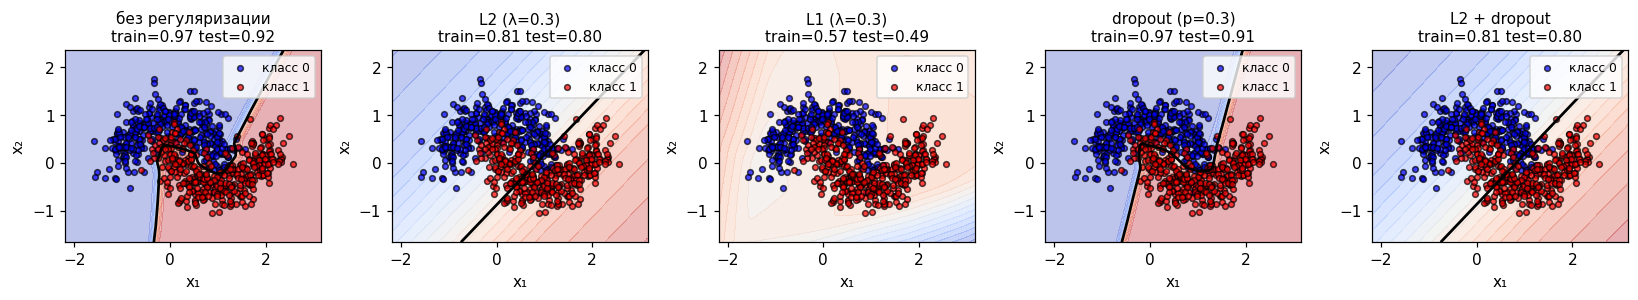

In [31]:
# специально маленькая ОБУЧАЮЩАЯ выборка - так overfit виден ярко,
# но большой тестовый набор, чтобы accuracy была гладкой
Xsm_all, ysm_all = make_moons(800, noise=0.25, seed=2)
Xsm_tr, ysm_tr, Xsm_te, ysm_te = split(Xsm_all, ysm_all, 80, seed=2)
print('train:', Xsm_tr.shape[0], ' test:', Xsm_te.shape[0], ' классы в train:', np.bincount(ysm_tr))

configs = {
    'без регуляризации': dict(reg=0.0),
    'L2 (λ=0.3)': dict(reg=0.3, reg_type='l2'),
    'L1 (λ=0.3)': dict(reg=0.3, reg_type='l1'),
    'dropout (p=0.3)': dict(dropout=0.3),
    'L2 + dropout': dict(reg=0.3, dropout=0.3),
}
results = {}
for name, cfg in configs.items():
    net, hist = train_classifier(Xsm_tr, ysm_tr, Xsm_te, ysm_te, H=64, batch_size=16,
                                 lr=0.2, epochs=60, seed=0, **cfg)
    results[name] = (net, hist)
    print(f'{name:>18}: train={hist["train_acc"][-1]:.3f}  test={hist["val_acc"][-1]:.3f}  '
          f'разрыв={hist["train_acc"][-1]-hist["val_acc"][-1]:+.3f}')

fig, axes = plt.subplots(1, len(results), figsize=(15, 3.4))
for ax, (name, (net, hist)) in zip(axes, results.items()):
    plot_decision(ax, Xsm_te, ysm_te, net, title=f'{name}\ntrain={hist["train_acc"][-1]:.2f} test={hist["val_acc"][-1]:.2f}')
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
plt.tight_layout(); plt.show()

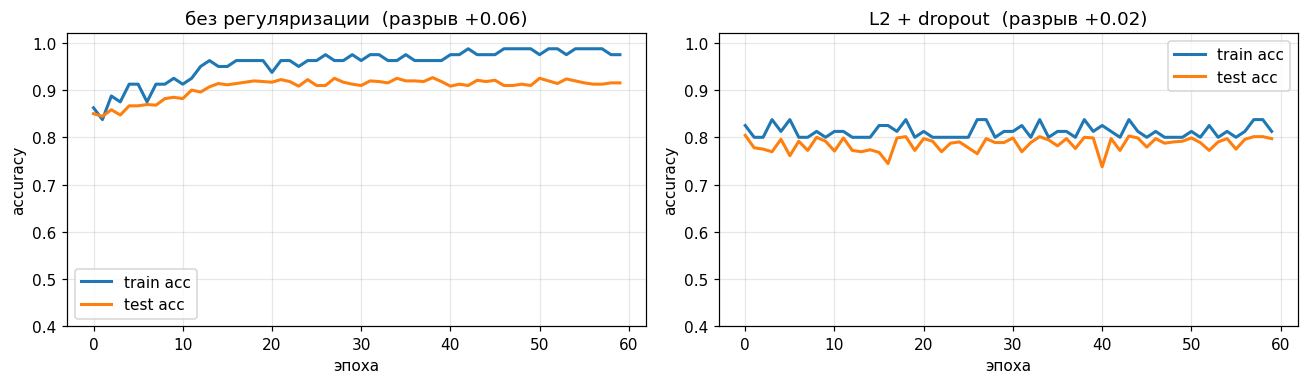

Без регуляризации train уходит в 1.0, а test отстаёт — это классический overfit.
Регуляризация не даёт train оторваться от test так сильно.


In [32]:
# кривые train/test accuracy для крайних случаев — нагляднее всего виден overfit
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, name in zip(axes, ['без регуляризации', 'L2 + dropout']):
    net, hist = results[name]
    ax.plot(hist['train_acc'], lw=2, label='train acc')
    ax.plot(hist['val_acc'], lw=2, label='test acc')
    gap = hist['train_acc'][-1] - hist['val_acc'][-1]
    ax.set_title(f'{name}  (разрыв {gap:+.2f})')
    ax.set_xlabel('эпоха'); ax.set_ylabel('accuracy'); ax.set_ylim(0.4, 1.02)
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('Без регуляризации train уходит в 1.0, а test отстаёт — это классический overfit.')
print('Регуляризация не даёт train оторваться от test так сильно.')

## 5.7. Другие виды регуляризации

Кроме штрафов и dropout есть ещё целое семейство:

| Метод | Идея | Комментарий |
|---|---|---|
| **Early stopping** | остановиться, когда val-loss начал расти | самый дешёвый; val-выборка играет роль «стоп-крана» |
| **Data augmentation** | генерировать новые примеры (повороты, шум, кропы) | лучшее лекарство от переобучения; особенно для картинок |
| **Dropout** | случайно выключать нейроны | ансамбль под-сетей |
| **L2 / weight decay** | штраф за большие веса | гладкость |
| **L1** | штраф за модули | разреженность и отбор признаков |
| **Label smoothing** | мягкие метки вместо one-hot | не даёт логитам «улетать» в бесконечность |
| **Noise injection** | шум в входы/веса/активации | стохастическая устойчивость |
| **BatchNorm** | нормировка активаций | регуляризует попутно (часть 6) |
| **Ensembling** | усреднить несколько моделей | надёжно, но дорого |
| **Weight sharing** | одни веса на несколько мест (CNN) | сильное ограничение модели |

Показательная связь bias–variance: регуляризация **увеличивает bias** (модель становится «проще») и **уменьшает variance** (меньше реагирует на шум). Задача — найти баланс $\lambda$.

![Полиномы: с ростом степени bias падает, variance растёт; суммарная ошибка — U-образная](https://upload.wikimedia.org/wikipedia/commons/thumb/9/9f/Bias_and_variance_contributing_to_total_error.svg/960px-Bias_and_variance_contributing_to_total_error.svg.png)

*Внешняя картинка: [Bias and variance contributing to total error](https://commons.wikimedia.org/wiki/File:Bias_and_variance_contributing_to_total_error.svg), Wikimedia Commons.*

### 5.8. Интерактив: сила регуляризации λ

Покрутите $\lambda$. Малое значение → overfit (train ≫ test, изрезанная граница). Большое → underfit (обе точности низкие, граница слишком простая). Ищите середину.

In [33]:
def reg_probe(log_lambda=0.0, epochs=60):
    lam = 10 ** log_lambda
    net, hist = train_classifier(Xsm_tr, ysm_tr, Xsm_te, ysm_te, H=64, batch_size=16,
                                 lr=0.2, epochs=epochs, seed=0, reg=lam)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    plot_decision(axes[0], Xsm_te, ysm_te, net,
                  title=f'λ={lam:.4f}\ntrain={hist["train_acc"][-1]:.2f} test={hist["val_acc"][-1]:.2f}')
    axes[0].set_xlabel('x₁'); axes[0].set_ylabel('x₂')
    axes[1].plot(hist['train_acc'], lw=2, label='train'); axes[1].plot(hist['val_acc'], lw=2, label='test')
    axes[1].set_ylim(0.4, 1.02); axes[1].set_xlabel('эпоха'); axes[1].set_ylabel('accuracy')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


display(widgets.interact(reg_probe,
        log_lambda=widgets.FloatSlider(value=-3, min=-6, max=1, step=0.1, description='log₁₀λ')))

interactive(children=(FloatSlider(value=-3.0, description='log₁₀λ', max=1.0, min=-6.0), IntSlider(value=60, de…

<function __main__.reg_probe(log_lambda=0.0, epochs=60)>

## 5.9. Итог по части 5

- Регуляризация борется с переобучением: не даёт модели подстроиться под шум.
- **L2** ($+\lambda W$) сжимает веса, даёт гладкие решения. **L1** ($+\lambda\,\mathrm{sign}(W)$) даёт разреженность.
- **Dropout** случайно выключает нейроны при обучении (с inverted-масштабом) — ансамбль под-сетей; на инференсе выключен.
- Есть ещё early stopping, augmentation, label smoothing и др. — все они ограничивают «сложность» модели.

---
# Часть 6. BatchNorm: как работает и почему ускоряет обучение

## 6.1. Проблема: распределение входов каждого слоя «плывёт»

В глубокой сети каждый слой получает не исходные данные, а активации предыдущего. В процессе обучения веса всех слоёв меняются, и **распределение входов каждого слоя постоянно сдвигается**. Это называют **internal covariate shift**.

Пример на пальцах: слой 3 настроился на входы со средним $0$ и дисперсией $1$. Через 100 шагов слой 2 сдвинул свои выходы к среднему $5$ и дисперсии $20$ — и слою 3 приходится «догонять», хотя его собственная задача не изменилась. Обучение становится медленным и чувствительным к lr и инициализации.

Идея BatchNorm: **принудительно нормировать активации** каждого слоя по батчу, чтобы распределение входов было стабильным.

## 6.2. Прямой проход BatchNorm

Для батча $x_1,\dots,x_n \in \mathbb{R}^{h}$ (для каждого признака $j$ независимо):

**Шаг 1 — центрирование и нормировка по батчу:**

$$\mu_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij},
\qquad
\sigma_j^2 = \frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\mu_j)^2,
\qquad
\boxed{\ \hat x_{ij} = \frac{x_{ij}-\mu_j}{\sqrt{\sigma_j^2 + \varepsilon}}\ }$$

Теперь каждый признак по батчу имеет среднее $0$ и дисперсию $1$ (а $\varepsilon$ спасает от деления на ноль).

**Шаг 2 — восстановление выразительности learnable-параметрами:**

$$\boxed{\ y_{ij} = \gamma_j\,\hat x_{ij} + \beta_j\ }$$

Зачем $\gamma$ и $\beta$? Нормировка — очень сильное ограничение: если бы мы жёстко требовали «среднее 0, дисперсия 1», мы бы выкинули полезную информацию (например, что одному нейрону нужен большой разброс). $\gamma,\beta$ — обучаемые: сеть может «отменить» нормировку (при $\gamma=\sqrt{\sigma^2+\varepsilon}$, $\beta=\mu$ получим тождество) или задать любой удобный масштаб. Это **нелинейность не добавляет** — при желании слой умеет быть identity.

**Важно про режимы:**

| Режим | Что используем для $\mu, \sigma^2$ | Зачем |
|---|---|---|
| **train** | статистики **текущего батча** | нормируем по данным |
| **eval / inference** | **running**-статистики, накопленные за обучение | у нас может не быть батча (один пример) |

Running-статистики обновляются скользящим средним:
$$\mu_{\text{run}} \leftarrow (1-m)\,\mu_{\text{run}} + m\,\mu, \qquad
\sigma^2_{\text{run}} \leftarrow (1-m)\,\sigma^2_{\text{run}} + m\,\sigma^2$$
($m$ — momentum, обычно $0.1$). Поэтому на инференсе BatchNorm — это **фиксированное линейное преобразование**: можно «вморозить» в соседний слой без потери скорости.

## 6.3. Обратный проход BatchNorm

Вывод градиента: нормировка — гладкая функция всех элементов батча, поэтому каждый $x_{ij}$ влияет на loss и через свою нормировку, и через $\mu_j,\sigma_j^2$, которые зависят от **всего** батча. Применяя chain rule и аккуратно суммируя вклады, получаем:

$$\boxed{\,d\gamma_j = \sum_i dY_{ij}\,\hat x_{ij}, \qquad db_j \equiv d\beta_j = \sum_i dY_{ij}\,}$$

$$\boxed{\,dX_{ij} = \frac{\gamma_j}{\sqrt{\sigma_j^2+\varepsilon}}\cdot\frac{1}{n}\left(n\,dY_{ij} - \sum_k dY_{kj} - \hat x_{ij}\sum_k dY_{kj}\,\hat x_{kj}\right)\,}$$

Смысл множителя в скобках: он **вычитает** общий сдвиг батча (члены с суммами), чтобы градиент учитывал, что батч нормирован целиком. При $n=1$ скобка обнуляется — вот почему BatchNorm нельзя обучать на батче из одного примера (и почему на инференсе нужны running-статистики).

Ниже — реализация и обязательная численная проверка.

In [34]:
class BatchNorm(Layer):
    '''BatchNorm по последней оси: y = gamma * (x - mu)/sqrt(var+eps) + beta.'''

    def __init__(self, n_features, eps=1e-5, momentum=0.1):
        self.gamma = np.ones(n_features)
        self.beta = np.zeros(n_features)
        self.dgamma = np.zeros(n_features)
        self.dbeta = np.zeros(n_features)
        self.running_mean = np.zeros(n_features)
        self.running_var = np.ones(n_features)
        self.eps = eps
        self.momentum = momentum
        self.training = True

    def forward(self, x):
        if self.training:
            self.mu = x.mean(axis=0)
            self.var = x.var(axis=0)
            self.xhat = (x - self.mu) / np.sqrt(self.var + self.eps)
            self.n = x.shape[0]
            # обновляем running-статистики (для инференса)
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * self.mu
            self.running_var = (1 - self.momentum) * self.running_var + self.momentum * self.var
        else:
            self.xhat = (x - self.running_mean) / np.sqrt(self.running_var + self.eps)
        return self.gamma * self.xhat + self.beta

    def backward(self, dY):
        self.dgamma = (dY * self.xhat).sum(axis=0)
        self.dbeta = dY.sum(axis=0)
        std_inv = 1.0 / np.sqrt(self.var + self.eps)
        n = self.n
        dxhat = dY * self.gamma
        dX = (std_inv / n) * (n * dxhat
                              - dxhat.sum(axis=0)
                              - self.xhat * (dxhat * self.xhat).sum(axis=0))
        return dX

    def params(self):
        return [('gamma', self.gamma, self.dgamma), ('beta', self.beta, self.dbeta)]


# ---- численная проверка BatchNorm ----
r = np.random.default_rng(3)
bn = BatchNorm(4); bn.training = True
Xb = r.normal(3.0, 2.0, size=(7, 4))
Y = bn.forward(Xb)
GY = r.normal(size=(7, 4))

dX_an = bn.backward(GY)
dgamma_an, dbeta_an = bn.dgamma.copy(), bn.dbeta.copy()

check_grad('BatchNorm dX', lambda x: np.sum(BatchNorm(4).forward(x) * GY), Xb, dX_an)
check_grad('BatchNorm dgamma', lambda g: np.sum((g * bn.xhat + bn.beta) * GY), bn.gamma, dgamma_an)
check_grad('BatchNorm dbeta', lambda b: np.sum((bn.gamma * bn.xhat + b) * GY), bn.beta, dbeta_an)
print('BatchNorm: forward нормирует, backward проверен численно.')

[OK ] BatchNorm dX         max|analytic - numeric| = 1.93e-09  (tol 1e-06)
[OK ] BatchNorm dgamma     max|analytic - numeric| = 6.04e-10  (tol 1e-06)
[OK ] BatchNorm dbeta      max|analytic - numeric| = 8.03e-10  (tol 1e-06)
BatchNorm: forward нормирует, backward проверен численно.


## 6.4. Почему обучение сильно ускоряется

**Классическое объяснение (в духе исходной статьи Ioffe & Szegedy, 2015):**
BN убирает «дрейф» распределений активаций, поэтому каждый слой учится на стабильном входе. Как следствие:

1. **Можно брать большой learning rate.** Без BN большой lr приводит к расходимости: слои «рассинхронизируются». Нормировка удерживает масштаб активаций, и сеть выдерживает lr в разы больше.
2. **Меньше зависимость от инициализации.** Даже при неудачном масштабе весов BN приводит активации к нормальному масштабу.
3. **Градиенты лучше себя ведут.** Нормировка не даёт затухать/взрываться сигналам; это сглаживает ландшафт функции потерь.
4. **Побочная регуляризация.** Статистики считаются по батчу → в forward есть шум → лёгкий эффект как у dropout (иногда BN заменяет dropout).

(В 2018 г. Santurkar и соавторы показали, что «internal covariate shift» — не главная причина; ключевое — что BN делает **ландшафт loss более гладким** и его градиенты — более предсказуемыми: $\|\nabla J\|$ и константа Липшица убывают. Но с практической точки зрения эффект один: **устойчивее, быстрее, терпимее к lr**.)

**Важная деталь:** BN после линейного слоя ставится **до** activation: `Linear → BN → ReLU`. Для ReLU нормировка перед ней особенно важна, чтобы половина нейронов не «залипала» в нуле.

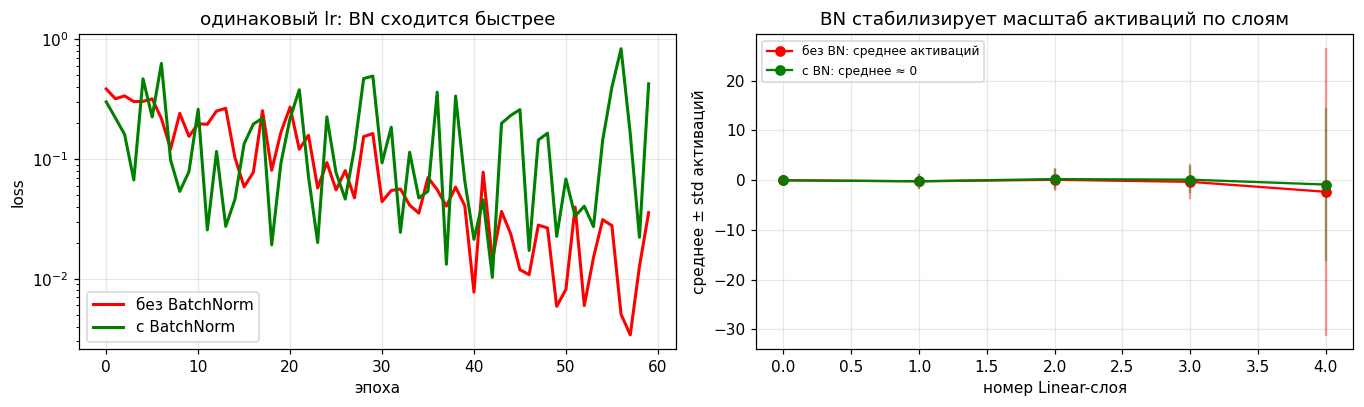

In [35]:
# Визуализация: как BN выравнивает распределения активаций по слоям
def layer_activations(net, X, n_layers=4):
    '''Собираем активации после каждого Linear-слоя, не меняя параметры.'''
    set_train(net, False)
    stats = []
    x = X
    for layer in net.layers:
        if isinstance(layer, Linear):
            x = layer.forward(x)
            stats.append((x.mean(axis=0).mean(), x.std(axis=0).mean()))
    return stats


def make_deep(bn, seed=0, width=32, depth=4):
    '''Глубокая сеть только для демонстрации стабильности активаций.'''
    layers, d = [], 2
    for i in range(depth):
        layers.append(Linear(d, width, init='he', seed=seed + i))
        if bn:
            layers.append(BatchNorm(width))
        layers.append(ReLU())
        d = width
    layers.append(Linear(d, 2, init='he', seed=seed + 99))
    return Sequential(*layers)


def train_plain(net, X, y, epochs=60, lr=0.1, batch_size=32, seed=0):
    rr = np.random.default_rng(seed)
    hist = []
    for ep in range(epochs):
        set_train(net, True)
        idx = rr.permutation(len(X))
        for s in range(0, len(X), batch_size):
            b = idx[s:s + batch_size]
            logits = net.forward(X[b])
            sce = SoftmaxCrossEntropy(); loss = sce.forward(logits, y[b])
            net.zero_grad(); net.backward(sce.backward()); net.sgd_step(lr)
        hist.append(loss)
    return net, hist


net_no_bn = make_deep(bn=False, seed=0)
_, h_no = train_plain(net_no_bn, Xtr, ytr, epochs=60, lr=0.05)

net_bn = make_deep(bn=True, seed=0)
_, h_bn = train_plain(net_bn, Xtr, ytr, epochs=60, lr=0.05)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].plot(h_no, 'r-', lw=2, label='без BatchNorm')
axes[0].plot(h_bn, 'g-', lw=2, label='с BatchNorm')
axes[0].set_yscale('log'); axes[0].set_xlabel('эпоха'); axes[0].set_ylabel('loss')
axes[0].set_title('одинаковый lr: BN сходится быстрее'); axes[0].legend(); axes[0].grid(alpha=0.3)

st_no = layer_activations(net_no_bn, Xtr)
st_bn = layer_activations(net_bn, Xtr)
xs = np.arange(len(st_no))
axes[1].plot(xs, [s[0] for s in st_no], 'ro-', label='без BN: среднее активаций')
axes[1].plot(xs, [s[0] for s in st_bn], 'go-', label='с BN: среднее ≈ 0')
for x, s in zip(xs, st_no):
    axes[1].plot([x, x], [s[0] - s[1], s[0] + s[1]], 'r-', alpha=0.4)
for x, s in zip(xs, st_bn):
    axes[1].plot([x, x], [s[0] - s[1], s[0] + s[1]], 'g-', alpha=0.4)
axes[1].set_xlabel('номер Linear-слоя'); axes[1].set_ylabel('среднее ± std активаций')
axes[1].set_title('BN стабилизирует масштаб активаций по слоям')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 6.5. Что именно стабилизирует BN: смотрим на распределения

Пройдём по слоям и сравним распределения активаций: без BN они «уползают» и меняют масштаб, с BN — всегда примерно $\mathcal{N}(0, 1)$-образные до того, как их преобразуют $\gamma,\beta$.

![Нормальное распределение: BN приводит активации к такому виду (среднее 0, дисперсия 1)](https://upload.wikimedia.org/wikipedia/commons/thumb/7/74/Normal_Distribution_PDF.svg/960px-Normal_Distribution_PDF.svg.png)

*Внешняя картинка: [Normal Distribution PDF](https://commons.wikimedia.org/wiki/File:Normal_Distribution_PDF.svg), Wikimedia Commons.*

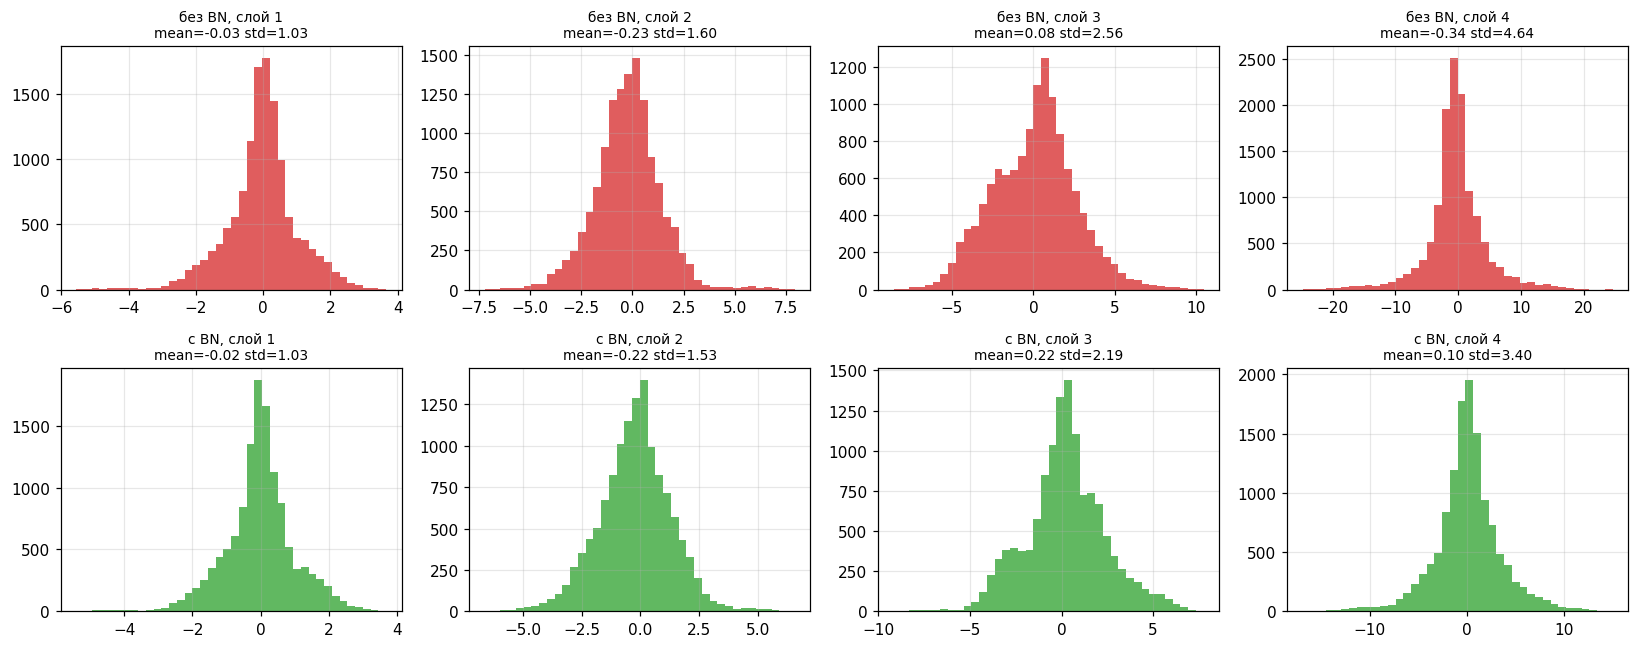

Без BN распределения по слоям «плывут» и имеют разный масштаб; с BN — стабильны.


In [36]:
def activations_by_layer(net, X):
    set_train(net, False)
    outs, x = [], X
    for layer in net.layers:
        if isinstance(layer, Linear):
            x = layer.forward(x)
            outs.append(x.copy())
    return outs


fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=False)
for row, (net, name) in enumerate([(net_no_bn, 'без BN'), (net_bn, 'с BN')]):
    acts = activations_by_layer(net, Xtr)
    for col in range(4):
        a = acts[col]
        axes[row, col].hist(a.ravel(), bins=40, color=('tab:red' if row == 0 else 'tab:green'), alpha=0.75)
        axes[row, col].set_title(f'{name}, слой {col+1}\nmean={a.mean():.2f} std={a.std():.2f}', fontsize=9)
        axes[row, col].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('Без BN распределения по слоям «плывут» и имеют разный масштаб; с BN — стабильны.')

## 6.6. Главный практический выигрыш: большой learning rate

Проверим утверждение «BN позволяет большой lr» экспериментально. Обучим сети с BN и без при разных lr и посмотрим, где обучение расходится.

Это, пожалуй, самая частая причина, по которой BN включают в архитектуру: он покупает **устойчивость к гиперпараметру lr**.

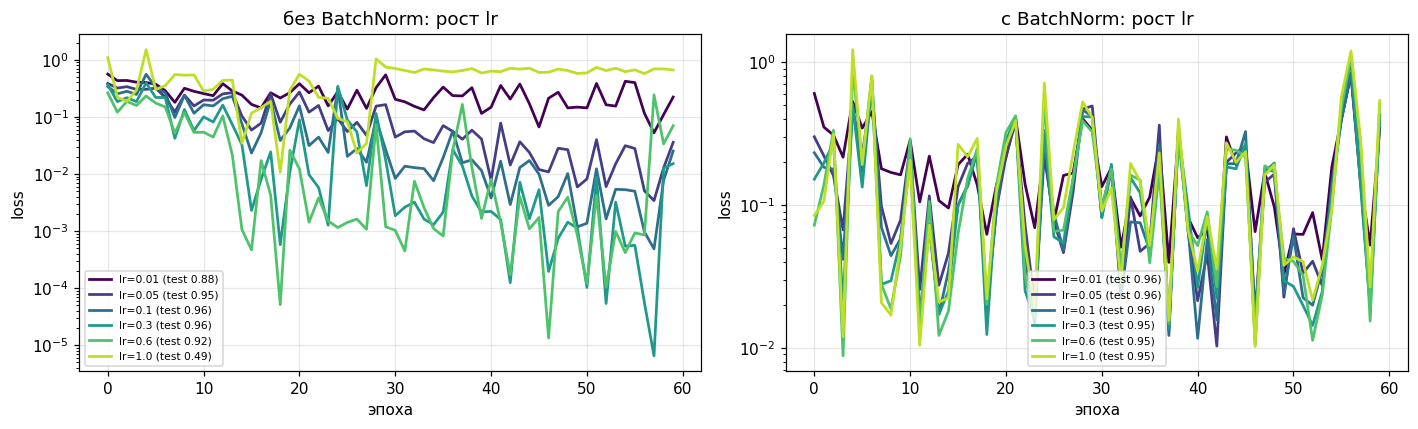

Без BN большие lr приводят к «пиле»/расходимости; с BN кривые остаются управляемыми.


In [37]:
lrs = [0.01, 0.05, 0.1, 0.3, 0.6, 1.0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, use_bn in zip(axes, [False, True]):
    for lr, c in zip(lrs, plt.cm.viridis(np.linspace(0, 0.9, len(lrs)))):
        net = make_deep(bn=use_bn, seed=0)
        _, hist = train_plain(net, Xtr, ytr, epochs=60, lr=lr)
        acc = accuracy(net, Xte, yte)
        ax.plot(hist, color=c, lw=1.8, label=f'lr={lr} (test {acc:.2f})')
    ax.set_yscale('log'); ax.set_xlabel('эпоха'); ax.set_ylabel('loss')
    ax.set_title(('без BatchNorm' if not use_bn else 'с BatchNorm') + ': рост lr')
    ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('Без BN большие lr приводят к «пиле»/расходимости; с BN кривые остаются управляемыми.')

## 6.7. Гладкость ландшафта потерь

Ещё один взгляд: якобы BN «сглаживает» функцию потерь. Идея в том, что при **малых изменениях параметров** loss меняется плавно, без резких обрывов.

Измерим напрямую: возьмём две точки в пространстве параметров (инициализация и обученная сеть) и проедем по прямой между ними, записывая loss. У гладкого ландшафта кривая ведёт себя аккуратнее, а разброс градиента по этой линии меньше. Сравним сети с BN и без.

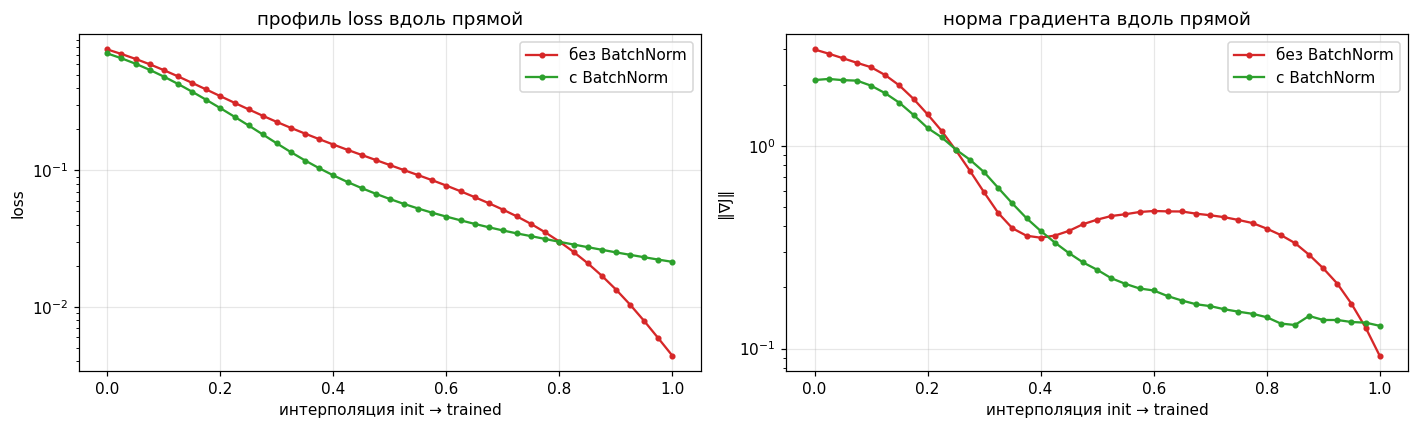

С BN кривые ведут себя «спокойнее»: меньше скачков и разброса градиента вдоль линии.


In [38]:
def interp_profile(use_bn, seed=1, epochs=80, lr=0.1, steps=41):
    '''Loss вдоль прямой от инициализации к обученным параметрам.'''
    net = make_deep(bn=use_bn, seed=seed)
    init = [v.copy() for _, v, _ in net.params()]
    train_plain(net, Xtr, ytr, epochs=epochs, lr=lr, seed=seed)
    trained = [v.copy() for _, v, _ in net.params()]

    probe = make_deep(bn=use_bn, seed=seed)
    ts = np.linspace(0, 1, steps)
    losses, gnorms = [], []
    for t in ts:
        for (name, v, _), A, B in zip(probe.params(), init, trained):
            v[...] = (1 - t) * A + t * B
        set_train(probe, True)                 # BN нормирует по батчу - так и меряем
        probe.zero_grad()
        logits = probe.forward(Xtr)
        sce = SoftmaxCrossEntropy()
        losses.append(sce.forward(logits, ytr))
        probe.backward(sce.backward())
        gnorms.append(np.sqrt(sum(float((g**2).sum()) for _, _, g in probe.params())))
    return ts, np.array(losses), np.array(gnorms)


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for use_bn, c, lab in [(False, 'tab:red', 'без BatchNorm'), (True, 'tab:green', 'с BatchNorm')]:
    ts, lss, gns = interp_profile(use_bn)
    axes[0].plot(ts, lss, 'o-', ms=3, color=c, label=lab)
    axes[1].plot(ts, gns, 'o-', ms=3, color=c, label=lab)
axes[0].set_yscale('log'); axes[0].set_xlabel('интерполяция init → trained'); axes[0].set_ylabel('loss')
axes[0].set_title('профиль loss вдоль прямой'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_yscale('log'); axes[1].set_xlabel('интерполяция init → trained'); axes[1].set_ylabel('‖∇J‖')
axes[1].set_title('норма градиента вдоль прямой'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('С BN кривые ведут себя «спокойнее»: меньше скачков и разброса градиента вдоль линии.')

## 6.8. Интерактив: BN в train vs eval

Ключевая практическая деталь: BatchNorm ведёт себя **по-разному** при обучении и на инференсе. Покрутите momentum и посмотрите, насколько быстро running-статистики догоняют истинное распределение активаций, и как отличаются предсказания в режиме `train` (по батчу) и `eval` (по running).

In [39]:
def bn_probe(momentum=0.1, batch_size=16, epochs=40):
    net = build_net(2, 32, 2, seed=0, bn=True)
    rr = np.random.default_rng(0)
    set_train(net, True)
    for ep in range(epochs):
        idx = rr.permutation(len(Xtr))
        for s in range(0, len(Xtr), batch_size):
            b = idx[s:s + batch_size]
            logits = net.forward(Xtr[b])
            sce = SoftmaxCrossEntropy(); sce.forward(logits, ytr[b])
            net.zero_grad(); net.backward(sce.backward()); net.sgd_step(0.2)

    bn_layer = [l for l in net.layers if isinstance(l, BatchNorm)][0]
    set_train(net, False)
    acts = net.layers[0].forward(Xtr)                # линейный выход
    true_mean, true_var = acts.mean(0), acts.var(0)

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
    axes[0].plot(bn_layer.running_mean, 'o-', label='running_mean')
    axes[0].plot(true_mean, 's--', label='истинное среднее')
    axes[0].set_title('running-статистики догоняют распределение')
    axes[0].set_xlabel('нейрон'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
    axes[1].plot(bn_layer.running_var, 'o-', label='running_var')
    axes[1].plot(true_var, 's--', label='истинная дисперсия')
    axes[1].set_yscale('log'); axes[1].set_xlabel('нейрон')
    axes[1].set_title('дисперсия активаций'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


display(widgets.interact(bn_probe,
        momentum=widgets.FloatSlider(value=0.1, min=0.01, max=0.9, step=0.01, description='momentum'),
        batch_size=widgets.SelectionSlider(options=[4, 8, 16, 32, 64], value=16, description='batch'),
        epochs=widgets.IntSlider(value=40, min=10, max=100, step=10, description='эпох')))

interactive(children=(FloatSlider(value=0.1, description='momentum', max=0.9, min=0.01, step=0.01), SelectionS…

<function __main__.bn_probe(momentum=0.1, batch_size=16, epochs=40)>

## 6.9. Итог по части 6

- BatchNorm **нормирует активации по батчу** ($\hat x = (x-\mu)/\sqrt{\sigma^2+\varepsilon}$) и затем восстанавливает гибкость learnable-параметрами $\gamma,\beta$.
- В **train** использует статистики батча (и обновляет running-оценки), в **eval** — running-статистики. Поэтому у слоя есть флаг `training`.
- Ускоряет обучение потому что: стабилизирует масштаб активаций, позволяет **большой lr**, снижает чувствительность к инициализации и делает ландшафт loss глаже (плюс лёгкая регуляризация).
- Ставится обычно так: `Linear → BatchNorm → ReLU`. На инференсе сворачивается в линейное преобразование → бесплатно по скорости.

Градиент мы вывели и проверили численно, как и все остальные слои.

---
# Итоги лекции

**1. Слои с нуля.** Мы реализовали `Linear`, `ReLU`, `Sigmoid`, `Softmax`, `LogLoss` (и слитый `SoftmaxCrossEntropy`) как классы с `forward`/`backward`, вывели формулы каждого прохода руками и **каждый градиент проверили численно**.

**2. Граф вычислений.** Нейросеть — это композиция функций $J = f_L \circ \dots \circ f_1$, а градиент считается по **chain rule**. Мы автоматизировали это двумя способами (`Sequential` и мини-`autograd` на `Node`) и увидели, что обратный проход просто перемножает локальные наклоны (а при нескольких путях — складывает).

**3. Батчи.** Точный градиент — среднее по примерам; мини-батч даёт несмещённую оценку с шумом $\sim 1/\sqrt{B}$. Батч нужен ради скорости и векторизации; маленький батч шумнее, но делает больше шагов и часто обобщает лучше, большой — глаже, но требует большего lr.

**4. Инициализация.** Нули (и любая одинаковая инициализация) не ломают симметрию — сеть вырождается в один нейрон. Нужен случайный масштаб: $\mathrm{Var}(w)\approx 1/d_{in}$ (Xavier, для tanh) или $2/d_{in}$ (He, для ReLU).

**5. Регуляризация.** L2 добавляет $\lambda W$ к градиенту и сжимает веса (гладкость); L1 добавляет $\lambda\,\mathrm{sign}(W)$ и даёт разреженность; dropout случайно выключает нейроны при обучении; есть ещё early stopping и augmentation. Все они ограничивают сложность и уменьшают overfit.

**6. BatchNorm.** Нормирует активации по батчу ($\hat x = (x-\mu)/\sqrt{\sigma^2+\varepsilon}$) и восстанавливает масштаб через learnable $\gamma,\beta$. При обучении использует статистики батча, на инференсе — running-оценки. Ускоряет обучение: стабильный масштаб активаций, терпимость к большому lr, меньшая зависимость от инициализации, более гладкий ландшафт.

---

## Сопоставление с PyTorch

Всё, что мы написали руками, в PyTorch занимает несколько строк — потому что там тот же интерфейс `forward`/`backward`, только автоматизированный:

| Наш слой | PyTorch |
|---|---|
| `Linear` | `nn.Linear(d_in, d_out)` |
| `ReLU` | `nn.ReLU()` |
| `Sigmoid` | `nn.Sigmoid()` |
| `Softmax` | `nn.Softmax(dim=-1)` |
| `LogLoss` | `nn.BCELoss()` / `nn.BCEWithLogitsLoss()` |
| `SoftmaxCrossEntropy` | `nn.CrossEntropyLoss()` |
| `BatchNorm` | `nn.BatchNorm1d(h)` |
| `Dropout` | `nn.Dropout(p)` |
| `Sequential` | `nn.Sequential(...)` |
| `zero_grad` + `backward` + `sgd_step` | `opt.zero_grad(); loss.backward(); opt.step()` |
| мини-батчи | `DataLoader(dataset, batch_size=B, shuffle=True, num_workers=..., pin_memory=...)` |
| He/Xavier init | `nn.init.kaiming_normal_` / `nn.init.xavier_uniform_` |
| L2 | `optim.SGD(..., weight_decay=λ)` |

Соберём ту же сеть на PyTorch и убедимся, что она учится (и что API один в один).

In [40]:
# Та же архитектура на PyTorch - для сравнения API (если torch доступен)
try:
    import torch
    import torch.nn as nn

    torch.manual_seed(42)
    device = torch.device('cuda' if torch.cuda.is_available()
                          else 'mps' if torch.backends.mps.is_available() else 'cpu')

    model = nn.Sequential(
        nn.Linear(2, 16),
        nn.BatchNorm1d(16),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(16, 2),
    ).to(device)

    Xt = torch.tensor(Xtr, dtype=torch.float32)
    yt = torch.tensor(ytr, dtype=torch.long)
    Xv = torch.tensor(Xte, dtype=torch.float32, device=device)
    yv = torch.tensor(yte, dtype=torch.long, device=device)

    opt = torch.optim.SGD(model.parameters(), lr=0.3, weight_decay=1e-4)  # weight_decay = L2
    criterion = nn.CrossEntropyLoss()                                     # наш SoftmaxCrossEntropy

    # датасет держим на CPU, а батчи переносим на device в цикле (канонический паттерн)
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xt, yt), batch_size=32, shuffle=True,
        num_workers=2, pin_memory=(device.type == 'cuda'))

    for ep in range(30):
        model.train()
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True)   # DataLoader -> GPU
            yb = yb.to(device, non_blocking=True)
            opt.zero_grad()               # = net.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()               # = net.backward(...)
            opt.step()                    # = net.sgd_step(lr)
    model.eval()
    with torch.no_grad():
        acc = (model(Xv).argmax(1) == yv).float().mean().item()
    print(f'PyTorch, device={device}: test_acc={acc:.3f}')
    print('Всё то же самое — но backward/optimizer автоматические.')
except ImportError as e:
    print('torch не установлен, пропускаем:', e)

PyTorch, device=cuda: test_acc=0.940
Всё то же самое — но backward/optimizer автоматические.


## Что попробовать самому

1. Добавить слой `Tanh` и собрать `Sequential` с чередованием `Linear/Tanh` — сравнить с ReLU.
2. Реализовать `Momentum` и `Adam` поверх нашего `sgd_step` (нужно хранить буферы у параметров).
3. Сделать `LayerNorm` (нормировка по признакам внутри одного примера, а не по батчу) и сравнить с `BatchNorm` на батче размера 1.
4. Проверить на своей инициализации, что делает слишком большой $\lambda$ (underfit) и слишком маленький (overfit) — найти «золотую середину» по интерактиву из части 5.
5. Заменить `SoftmaxCrossEntropy` на `Softmax` + `LogLoss` в цикле обучения — убедиться, что результат тот же, но численно менее устойчиво.

## Полезные внешние ресурсы

- [TensorFlow Playground](https://playground.tensorflow.org) — вживую покрутить depth, lr, regularization, activation и увидеть границы решений.
- [Batch Normalization (Ioffe & Szegedy, 2015)](https://arxiv.org/abs/1502.03167) — оригинальная статья про BN.
- [How Does Batch Normalization Help Optimization? (Santurkar et al., 2018)](https://arxiv.org/abs/1805.11604) — почему BN на самом деле помогает.
- [Understanding the difficulty of training deep feedforward neural networks (Glorot & Bengio, 2010)](https://proceedings.mlr.press/v9/glorot10a.html) — откуда Xavier.
- [Delving Deep into Rectifiers (He et al., 2015)](https://arxiv.org/abs/1502.01852) — откуда He.
- [Dropout (Srivastava et al., 2014)](https://jmlr.org/papers/v15/srivastava14a.html).